# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Рудьман Иван Олегович.**

**Файлы данных:**

1. data/clients.csv;
2. data/transactions.csv.


## 0. Окружение и настройки

In [1]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS_PATH = "data/clients.csv"
RAW_TXN_PATH = "data/transactions.csv"

PERIOD_START = pd.Timestamp("2024-01-01")
PERIOD_END = pd.Timestamp("2025-06-30")

# буфер журнала изменений: одно решение — одна запись
log_rows = []

## 1. Загрузка сырых данных


### 1.1. Загрузка clients.csv


Наивно прочитаем файл с клиентами

In [2]:
df_clients = pd.read_csv(RAW_CLIENTS_PATH)
print('Размер таблицы:', df_clients.shape)
print('Типы столбцов:', df_clients.dtypes, sep = '\n')
df_clients.head(5)

Размер таблицы: (5719, 16)
Типы столбцов:
client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code             int64
marketing_opt_in          str
dtype: object


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002786,1960-11-04,Ж,Казань,Массовый,Базовый,Дебетовая,02.03.2021,22.06.2023,Зарплата в другом банке,52500.0,Нет,NaN,5.0,905,Да
1,C003601,1988-05-11,Ж,Казань,Массовый,Базовый,Дебетовая,09.12.2022,21.02.2025,Зарплата в нашем банке,57600.0,Нет,NaN,NaN,635,Нет
2,C003692,1976-10-16,Ж,СПб,Премиальный,Серебро,Дебетовая,18.09.2014,25.04.2018,Зарплата в нашем банке,105300.0,Да,2025-03,NaN,872,Да
3,C005100,1983-02-13,Ж,Н. Новгород,Зарплатный,Базовый,Кредитная,26.10.2019,18.03.2025,Зарплата в нашем банке,94800.0,Да,2025-03,NaN,443,Да
4,C001633,1976-05-24,М,Нижний Новгород,Массовый,Базовый,Дебетовая,20.04.2018,14.09.2021,Зарплата в другом банке,47700.0,Да,2025-03,2.0,598,Да


Файл прочитался хорошо, но видим, что категориальные типы не определились, а даты прочитались как строки. Исправим это в следующем блоке на основе данных вывода и Task.md.

In [3]:
df_clients = pd.read_csv(
    RAW_CLIENTS_PATH,
    dtype={
        'client_id': 'string',
        # категориальные признаки
        'gender': 'category',
        'city': 'category',
        'segment': 'category',
        'loyalty_tier': 'category',
        'card_type': 'category',
        'income_source': 'category',
        'has_mobile_app': 'category',
        'marketing_opt_in': 'category',
        # числовые признаки
        'monthly_income': 'float64',
        'satisfaction_score': 'Int64',   # 1..5, есть пропуски -> nullable int
        'branch_code': 'int64',
        # даты читаем как строки и парсим отдельно (форматы разные)
        'birth_date': 'string',
        'registration_date': 'string',
        'card_open_date': 'string',
        'app_last_login': 'string',
    },
)

df_clients['birth_date']        = pd.to_datetime(df_clients['birth_date'],        format='%Y-%m-%d')
df_clients['registration_date'] = pd.to_datetime(df_clients['registration_date'], format='%d.%m.%Y')
df_clients['card_open_date']    = pd.to_datetime(df_clients['card_open_date'],    format='%d.%m.%Y')
df_clients['app_last_login']    = pd.to_datetime(df_clients['app_last_login'],    format='%Y-%m', errors='coerce')

print('Типы столбцов:', df_clients.dtypes, sep = '\n')

Типы столбцов:
client_id                     string
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score             Int64
branch_code                    int64
marketing_opt_in            category
dtype: object


## 1.2 transactions.csv

Попробуем прочитать наивно:


In [4]:
try:
    df_transactions = pd.read_csv(RAW_TXN_PATH)
except Exception as e:
    print('Ошибка при чтении файла:', e)

Ошибка при чтении файла: 'utf-8' codec can't decode byte 0xce in position 7: invalid continuation byte


Предположим, что кодировка файла cp1251, т.к. данные на кириллице:


In [5]:
df_transactions = pd.read_csv(RAW_TXN_PATH, encoding = 'cp1251')
print('Размер таблицы:', df_transactions.shape)
print('Типы столбцов:', df_transactions.dtypes, sep = '\n')
df_transactions.head(5)

Размер таблицы: (625276, 1)
Типы столбцов:
txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status    str
dtype: object


,txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status
990163;C001976;2023-12-10;4638,38;RUB;Одежда и обувь;5651;Карта;успешно
990199;C004215;2023-12-12 12:19:56;507,22;RUB;Продукты;5411;Карта;успешно
990072;C004029;2023-12-17 13:59:08;902,94;RUB;Продукты;5411;Карта;успешно
990033;C001144;2023-12-17 14:36:01;247,73;RUB;Продукты;5411;Карта;успешно
990046;C001369;2023-12-28 06:54:01;135,79;RUB;Транспорт;4111;Карта;успешно


Данные слиплись, т.к. сепаратором в данных является символ `;`. Исправим это в следующем блоке. И сразу укажем нужные типы данных на основе того, что увидели.

In [6]:
df_transactions = pd.read_csv(
    RAW_TXN_PATH,
    dtype={
        'txn_id': 'Int64',
        'client_id': 'string',
        'txn_datetime': 'string',
        'amount': 'string',
        'currency': 'category',
        'category': 'category',
        'mcc_code': 'Int64',
        'channel': 'category',
        'status': 'category',
    },
     encoding='cp1251', sep=';'
)

df_transactions['txn_datetime']    = pd.to_datetime(df_transactions['txn_datetime'], errors='coerce', format='mixed')
df_transactions['amount'] = df_transactions['amount'].str.replace(",", ".").astype('float64')


print('Размер таблицы:', df_transactions.shape)
df_transactions.head(5)

Размер таблицы: (625276, 9)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990163,C001976,2023-12-10 00:00:00,4638.38,RUB,Одежда и обувь,5651,Карта,успешно
1,990199,C004215,2023-12-12 12:19:56,507.22,RUB,Продукты,5411,Карта,успешно
2,990072,C004029,2023-12-17 13:59:08,902.94,RUB,Продукты,5411,Карта,успешно
3,990033,C001144,2023-12-17 14:36:01,247.73,RUB,Продукты,5411,Карта,успешно
4,990046,C001369,2023-12-28 06:54:01,135.79,RUB,Транспорт,4111,Карта,успешно


### 1.3. Итог загрузки

Файлы выгружены из разных систем, и это видно по трём признакам сразу:

| файл | кодировка | разделитель | десятичный разделитель | формат дат |
|---|---|---|---|---|
| `clients.csv` | UTF-8 | `,` | точка | `%d.%m.%Y` и `%Y-%m-%d` |
| `transactions.csv` | cp1251 | `;` | запятая | `%Y-%m-%d %H:%M:%S` |

Чтение «по умолчанию» дало ошибку кодировки у операций и один столбец вместо девяти. Поэтому параметры чтения заданы явно, а типы объявлены на входе: даты и числа разбираются один раз, при загрузке, а не заново в каждом блоке.

Результат: **5719 строк клиентов** и **625276 строк операций**.


## 2. Аудит качества

### 2.1. Объём, типы, ключи, единица наблюдения

In [7]:
# --- объём, ключи, единица наблюдения
print("clients.csv")
print(df_clients.dtypes.to_string())
print("\ntransactions.csv")
print(df_transactions.dtypes.to_string())

print("\nпериод операций в файле:", df_transactions["txn_datetime"].min().date(), "—", df_transactions["txn_datetime"].max().date())
print("заявленный период:", PERIOD_START.date(), "—", PERIOD_END.date())

missing = pd.DataFrame({"пропусков": df_clients.isna().sum(), "доля, %": (df_clients.isna().mean() * 100).round(1)})
print("\nпропуски в clients.csv (знаменатель —", len(df_clients), "строк):")
print(missing[missing["пропусков"] > 0].to_string())
print("\nсуммарно пропусков в transactions.csv:", int(df_transactions.isna().sum().sum()))

keys = pd.DataFrame(
    {
        "строк": [len(df_clients), len(df_transactions)],
        "уникальных ключей": [df_clients["client_id"].nunique(), df_transactions["txn_id"].nunique()],
        "единица наблюдения": ["клиент", "операция"],
    },
    index=["clients.csv", "transactions.csv"],
)
keys["строк сверх ключа"] = keys["строк"] - keys["уникальных ключей"]
keys


clients.csv
client_id                     string
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score             Int64
branch_code                    int64
marketing_opt_in            category

transactions.csv
txn_id                   Int64
client_id               string
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
mcc_code                 Int64
channel               category
status                category

период операций в файле: 2023-12-10 — 2026-08-01
заявленный период: 2024-01-01 — 2025-06-30

пропу

,строк,уникальных ключей,единица наблюдения,строк сверх ключа
clients.csv,5719,5664,клиент,55
transactions.csv,625276,623776,операция,1500


**Что видно.** Обе таблицы читаются, типы объяснимы, но в каждой есть «строки сверх ключа»: 55 у клиентов и 1500 у операций. Значит, прежде чем считать любую долю, нужно разобраться с дублями — иначе знаменатель завышен.

Пропуски есть только в справочнике: `monthly_income` 9.2%, `app_last_login` 38.8%, `satisfaction_score` 60.7% (знаменатель — 5719 строк файла). В операциях пропусков нет ни в одном поле.

Период в файле шире заявленного: 2023-12-10 … 2026-08-01 против 2024-01-01 … 2025-06-30.

Единица наблюдения разная: клиент в первой таблице и операция во второй. Поэтому «сколько клиентов» и «сколько операций» — разные знаменатели, и смешивать их в одной доле нельзя.


#### Проверка распределения txn_id

In [8]:
# --- Проверим распределение txn_id по месяцам

month = df_transactions["txn_datetime"].dt.to_period("M")
group_by_month = df_transactions.groupby(month)['txn_id']
pd.DataFrame(
    {
        "минимальный id": group_by_month.min(),
        "максимальный id": group_by_month.max(),
        "разница": group_by_month.max() - group_by_month.min(),
        "количество операций в периоде": group_by_month.count(),
    }
).sort_index()

,минимальный id,максимальный id,разница,количество операций в периоде
txn_datetime,,,,
2023-12,990031,990199,168,6
2024-01,100001,990127,890126,26600
2024-02,126533,990219,863686,33453
2024-03,159912,990204,830292,38650
2024-04,198458,990146,791688,37490
2024-05,235828,990215,754387,34507
2024-06,270252,990212,719960,37207
2024-07,307357,990200,682843,38125
2024-08,345391,990185,644794,39543


**Что видно**: Видны странные индексы в каждом месяце начинающиеся с 990, при этом каждый месяц начинается последовательно с индекса примерно соответсвующего его начальному индексу + сумма операций за предыдущий месяц. Отличаются только месяца вне периода который нам необходимо проанализировать. Попробуем проанализировать месяца в отсутсвие этих индексов:

In [9]:
def check_tnx_ids_distribution(transactions: pd.DataFrame, upper_id_limit: int = 990000) -> pd.DataFrame:
    """
    Получает на вход подвыборку транзакций и возвращает DataFrame с распределением txn_id по месяцам:
    минимальный и максимальный id, разницу между ними, количество операций в периоде и разность
    между ожиданием и фактом. Отбрасывает все id выше upper_id_limit.
    """
    transactions = transactions.loc[transactions["txn_id"].le(upper_id_limit)]

    month = transactions["txn_datetime"].dt.to_period("M")
    group_by_month = transactions["txn_id"].groupby(month)
    group_min = group_by_month.min()
    group_max = group_by_month.max()
    group_count = group_by_month.count()
    return pd.DataFrame(
        {
            "минимальный id": group_min,
            "максимальный id": group_max,
            "разница": group_max - group_min + 1,
            "количество операций в периоде": group_count,
            "разность между ожиданием и фактом": group_max + 1 - group_min - group_count,
        }
    ).sort_index()

check_tnx_ids_distribution(df_transactions)

,минимальный id,максимальный id,разница,количество операций в периоде,разность между ожиданием и фактом
txn_datetime,,,,,
2024-01,100001,126532,26532,26595,-63
2024-02,126533,159911,33379,33442,-63
2024-03,159912,198457,38546,38643,-97
2024-04,198458,235827,37370,37486,-116
2024-05,235828,270251,34424,34495,-71
2024-06,270252,307356,37105,37199,-94
2024-07,307357,345390,38034,38119,-85
2024-08,345391,384821,39431,39534,-103
2024-09,384822,422335,37514,37601,-87


**Что видно**: Разница между id максимальным и минимальным значением транзакций в месяце практически полностью соответствует их количеству, за исключением февраля и марта 2025 года. В этих месяцах, вероятно, пропущены строки транзакций при их выборке. В остальных месяцах разница не так значительна и имеет отрицательное значение, что, вероятно, свидетельствует о дубликатах. Эту информацию необходимо учесть при дальнейшем анализе, чтобы не получить смещенные оценки активности.

Также при удалении значений от 990000 исчезли данные по месяцам вне интересующего периода. Эти транзакции выглядят как примеси в основной датасет. 

### 2.2. Дубли

In [10]:
# --- клиенты: полные дубли и дубли по ключу
clients_exact = df_clients.drop_duplicates()
conflict = clients_exact["client_id"].duplicated(keep=False)

print("clients.csv, строк:", len(df_clients))
print("  полных дублей строк:", len(df_clients) - len(clients_exact))
print(
    "  client_id с противоречивыми атрибутами:",
    int(conflict.sum()),
    "строк /",
    int(clients_exact.loc[conflict, "client_id"].nunique()),
    "идентификаторов",
)

clients_exact.loc[conflict].sort_values("client_id")[
    ["client_id", "birth_date", "city", "segment", "loyalty_tier", "monthly_income"]
].head(10)


clients.csv, строк: 5719
  полных дублей строк: 40
  client_id с противоречивыми атрибутами: 30 строк / 15 идентификаторов


,client_id,birth_date,city,segment,loyalty_tier,monthly_income
335,C000317,1974-12-31,г. Санкт-Петербург,Зарплатный,Базовый,103200.0
5152,C000317,1974-12-31,Екатеринбург,Private,Базовый,103200.0
2993,C000490,1982-09-01,Нижний Новгород,Премиальный,Серебро,58200.0
4859,C000490,1982-09-01,Н. Новгород,Массовый,Серебро,58200.0
1435,C000501,1968-11-03,Казань,Массовый,Базовый,116200.0
2174,C000501,1968-11-03,Екатеринбург,Массовый,Базовый,116200.0
2873,C000608,1989-09-05,Казань,Private,Серебро,159200.0
2943,C000608,1989-09-05,г. Новосибирск,Премиальный,Серебро,159200.0
3823,C001338,1951-05-30,Нижний Новгород,Зарплатный,Серебро,67700.0
5332,C001338,1951-05-30,Новосибирск,Премиальный,Серебро,67700.0


In [11]:
# --- операции: полные дубли и дубли по ключу
txn_exact = df_transactions.drop_duplicates()
midnight = txn_exact["txn_datetime"].dt.time.eq(datetime.time(0, 0))
same_id = txn_exact.duplicated(subset=["txn_id"], keep=False)

print("transactions.csv, строк:", len(df_transactions))
print("  полных дублей строк:", len(df_transactions) - len(txn_exact))
print("  операций с потерянным временем (00:00:00 при наличии пары с точным временем):", int((midnight & same_id).sum()))
print("  записей 00:00:00 без пары по txn_id:", int((midnight & ~same_id).sum()))

txn_exact.loc[same_id].sort_values("txn_id")[
    ["txn_id", "client_id", "txn_datetime", "amount", "category"]
].head(10)


transactions.csv, строк: 625276
  полных дублей строк: 1281
  операций с потерянным временем (00:00:00 при наличии пары с точным временем): 219
  записей 00:00:00 без пары по txn_id: 49683


,txn_id,client_id,txn_datetime,amount,category
1037,101028,C005442,2024-01-02 13:26:45,1945.08,Продукты
1038,101028,C005442,2024-01-02 00:00:00,1945.08,Продукты
2297,102286,C003905,2024-01-04 12:17:50,76.51,Транспорт
2298,102286,C003905,2024-01-04 00:00:00,76.51,Транспорт
8470,108436,C005176,2024-01-10 13:38:46,423.02,Онлайн-сервисы
8471,108436,C005176,2024-01-10 00:00:00,423.02,Онлайн-сервисы
13451,113409,C000019,2024-01-16 00:00:00,1264.30,Развлечения и досуг
13452,113409,C000019,2024-01-16 17:20:35,1264.30,Развлечения и досуг
15301,115256,C001976,2024-01-19 00:00:00,4638.38,Одежда и обувь
15302,115256,C001976,2024-01-19 13:57:00,4638.38,Одежда и обувь


**Что видно.** У клиентов 40 полных дублей и 15 идентификаторов, у которых расходятся город и сегмент. Второе — не дубль, а два разных описания одного человека, и по данным нельзя выбрать верное.

У операций 1281 полный дубль и отдельная проблема: у 219 операций одна запись хранит `00:00:00`, а вторая — точное время при том же `txn_id`. При этом ещё 49 683 записи имеют `00:00:00` и пары не имеют: время теряется не только у дублей, а примерно у 8% операций. Для разреза по месяцам это не критично (дата сохранена), для «в какое время суток платят» такие записи непригодны.


### 2.3. Соответствие данных описанию полей из задания

In [12]:
print("city:", df_clients["city"].nunique(), "значений на", len(df_clients), "клиентов")
print(df_clients["city"].value_counts().to_string())

print("\ncategory:", df_transactions["category"].nunique(), "значений")
print(df_transactions["category"].value_counts().to_string())

mcc_mode = df_transactions.groupby("category", observed=True)["mcc_code"].agg(lambda s: s.mode().iloc[0])
off_mcc = df_transactions["mcc_code"].ne(df_transactions["category"].map(mcc_mode))
print("\nmcc_code не совпадает с ведущим кодом своей категории:", int(off_mcc.sum()), f"({off_mcc.mean():.2%})")
print(mcc_mode.to_string())


city: 17 значений на 5719 клиентов
city
Москва                1094
Казань                 712
Санкт-Петербург        665
Нижний Новгород        543
Новосибирск            541
Екатеринбург           488
казань                 213
 москва                211
МОСКВА                 201
г. Новосибирск         167
Н. Новгород            161
г. Москва              160
Санкт Петербург        122
ЕКАТЕРИНБУРГ           118
СПб                    115
г. Санкт-Петербург     109
г.Екатеринбург          99

category: 12 значений
category
Продукты               164490
Транспорт               71439
Одежда и обувь          64991
АЗС                     58008
Кафе и рестораны        48814
Развлечения и досуг     47712
Аптеки                  45046
Онлайн-сервисы          43616
Связь и интернет        29341
Связь и Интернет        19226
кафе и рестораны        16446
Кафе/рестораны          16147

mcc_code не совпадает с ведущим кодом своей категории: 1707 (0.27%)
category
АЗС                    5541
Апт

In [13]:
print("валюты:", df_transactions["currency"].value_counts().to_dict())
print("статусы:", df_transactions["status"].value_counts().to_dict())

negative = df_transactions["amount"].lt(0)
returns = df_transactions["status"].eq("возврат")
print("\nотрицательных сумм:", int(negative.sum()))
print("знак совпадает со статусом «возврат»:", bool(negative.eq(returns).all()))

out_of_period = ~df_transactions["txn_datetime"].dt.normalize().between(PERIOD_START, PERIOD_END)
print("\nопераций вне заявленного периода:", int(out_of_period.sum()))
print(df_transactions.loc[out_of_period, "txn_datetime"].dt.to_period("M").value_counts().sort_index().to_string())

income = df_clients["monthly_income"]
print("\nрежимы записи дохода:")
print("  пусто:", int(income.isna().sum()))
print("  заглушка -999:", int(income.lt(0).sum()))
print("  записано в тысячах (0 < x < 1000):", int((income.gt(0) & income.lt(1000)).sum()))
print("  в рублях (>= 1000):", int(income.ge(1000).sum()))

print("\napp_last_login пуст ровно у клиентов без приложения:", bool(df_clients["app_last_login"].isna().eq(df_clients["has_mobile_app"].eq("Нет")).all()))
print("branch_code:", df_clients["branch_code"].nunique(), "значений,", round(df_clients.groupby("branch_code", observed=True)["city"].nunique().mean(), 1), "города на отделение в среднем")


валюты: {'RUB': 622653, 'EUR': 1315, 'USD': 1308}
статусы: {'успешно': 605455, 'отклонено': 12273, 'возврат': 7548}

отрицательных сумм: 7548
знак совпадает со статусом «возврат»: True

операций вне заявленного периода: 85
txn_datetime
2023-12     6
2025-07     5
2025-08     5
2025-09    11
2025-10     4
2025-11     7
2025-12     5
2026-01     6
2026-02     7
2026-03     6
2026-04     7
2026-05     5
2026-06     7
2026-07     3
2026-08     1
Freq: M

режимы записи дохода:
  пусто: 525
  заглушка -999: 47
  записано в тысячах (0 < x < 1000): 174
  в рублях (>= 1000): 4973

app_last_login пуст ровно у клиентов без приложения: True
branch_code: 840 значений, 5.0 города на отделение в среднем


**Расхождения с описанием полей.**

1. `city` — 17 написаний на 6 реальных городов (регистр, приставка «г.», дефис или пробел).
2. `category` — 12 значений вместо девяти: «Кафе/рестораны», «кафе и рестораны», «Связь и Интернет».
3. `mcc_code` — описан как «соответствует категории», но 1707 строк (0.27%) несут код чужой категории; после удаления дублей и операций клиентов вне справочника (раздел 3.2) их остаётся 1606. Соответствие почти строгое, но не полное.
4. `status` — три значения, и отрицательные суммы есть ровно у возвратов (7548 из 7548): знак суммы не независим от статуса и сам по себе типом операции не является.
5. `txn_datetime` — 85 операций вне заявленного периода: 6 в декабре 2023 и 79 в июле 2025 — августе 2026.
6. `monthly_income` — три режима записи в одном поле: пропуск (525), заглушка −999 (47) и запись в тысячах (174).
7. `app_last_login` — пропуск строго совпадает с «приложение не установлено», то есть структурный, а не потерянный.
8. `branch_code` — 840 значений при 5649 клиентах и в среднем 5 городов на отделение: код не описывает ни клиента, ни географию.

Пункты 1 и 2 — дефекты записи, их видно по самим значениям. Пункт 8 — расхождение описания с фактом: файл не испорчен, но описание поля ему не соответствует, и это надо зафиксировать, а не «починить» данные под описание.


### 2.4. Связь между таблицами

In [14]:
in_reference = df_transactions["client_id"].isin(df_clients["client_id"])
without_ops = ~df_clients["client_id"].isin(df_transactions["client_id"])

print("уникальных client_id в операциях:", df_transactions["client_id"].nunique())
print("из них нет в справочнике:", df_transactions.loc[~in_reference, "client_id"].nunique())
print("строк операций без клиента в справочнике:", int((~in_reference).sum()), f"({(~in_reference).mean():.1%})")
print("клиентов справочника без единой операции:", int(without_ops.sum()))
print("клиентов справочника с операциями:", int((~without_ops).sum()), f"({(~without_ops).mean():.1%})")
print("клиентов с картой, открытой не раньше 01.01.2024:", int(df_clients["card_open_date"].ge(PERIOD_START).sum()))


уникальных client_id в операциях: 5985
из них нет в справочнике: 336
строк операций без клиента в справочнике: 29300 (4.7%)
клиентов справочника без единой операции: 15
клиентов справочника с операциями: 5704 (99.7%)
клиентов с картой, открытой не раньше 01.01.2024: 815


**Что видно.** Таблицы связаны по `client_id`, но связь неполная в обе стороны:

- в операциях 5985 уникальных клиентов, из них 336 нет в справочнике — это 29 300 строк, 4.7% строк файла, которые нельзя описать признаками клиента;
- 15 клиентов справочника не имеют ни одной операции за весь файл;
- у 815 клиентов карта открыта 01.01.2024 или позже, поэтому за часть базового периода операций у них быть не могло.

Отсюда правило на весь дальнейший анализ: показатель считается только на клиентах, у которых есть и справочник, и история операций, а клиенты с короткой историей не участвуют в сравнении периодов.


**Выводы по аудиту**

| находка | масштаб | чем мешает |
|---|---|---|
| разнобой кодировок и разделителей | оба файла | без явных параметров чтения один файл не читается, второй слипается в один столбец |
| полные дубли строк | 40 строк клиентов, 1281 операция | завышают знаменатель всех долей и частоту операций |
| один `client_id` — разные признаки | 15 идентификаторов, 30 строк | клиента нельзя описать правилом |
| потеря времени операции | 219 пар дублей и 49 683 записи с `00:00:00` | часовой разрез невозможен, месячный не задет |
| разнобой `city` | 17 написаний на 6 городов | группа «Москва» распалась бы на четыре |
| разнобой `category` | 12 значений на 9 категорий | частоты занижены в 1.5–2 раза |
| `mcc_code` не соответствует категории | 1707 строк (0.27%) | дублирует `category` с шумом, описание поля не подтверждено |
| заглушка −999 и запись в тысячах в `monthly_income` | 47 и 170 значений | среднее и максимум дохода искажены в десятки раз |
| пропуски в справочнике | 9.2%, 38.8%, 60.7% от 5719 строк | средние по этим полям считать нельзя, нужны медианы и явные знаменатели |
| операции без клиента в справочнике | 336 клиентов, 29 300 строк (4.7%) | такого клиента не отнести ни к одной группе |
| клиенты без операций | 15 | сравнивать нечего |
| карта открыта в 2024–2025 | 815 клиентов | нет полного базового периода |
| три валюты в поле суммы | 2623 операции | суммовые метрики требуют приведения к рублю |

Мешают эти находки по-разному, и это важно разделить. Дубли, разнобой написаний, сентинел и запись в тысячах — механические дефекты: их можно исправить, не изменив смысла. Неполная связь таблиц и короткая история новых карт — ограничение анализа: такие клиенты просто не участвуют в сравнении, и это надо назвать вслух. Валюта и `mcc_code` — расхождение описания с данными: фиксируем как находку и делаем выбор, а не «правим» файл под описание.


## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.0. Дубли и ключи

In [15]:
# --- клиенты: полные дубли и противоречивые записи
CLIENTS_RAW_ROWS = len(df_clients)
df_clients = df_clients.drop_duplicates()
clients_after_exact = len(df_clients)

conflict = df_clients["client_id"].duplicated(keep=False)
n_conflict = int(conflict.sum())
conflict_ids = df_clients.loc[conflict, "client_id"].unique()
n_conflict_ids = int(df_clients.loc[conflict, "client_id"].nunique())
df_clients = df_clients.loc[~conflict].copy()

print(f"clients.csv: {CLIENTS_RAW_ROWS} строк -> {len(df_clients)} клиентов")
print(f"  полных дублей: {CLIENTS_RAW_ROWS - clients_after_exact}")
print(f"  строк с противоречивыми атрибутами: {n_conflict} ({n_conflict_ids} id)")

# --- операции: полные дубли и записи с потерянным временем
TXN_RAW_ROWS = len(df_transactions)
df_transactions = df_transactions.drop_duplicates()
txn_after_exact = len(df_transactions)

midnight = df_transactions["txn_datetime"].dt.time.eq(datetime.time(0, 0))
lost_time = midnight & df_transactions.duplicated(subset=["txn_id"], keep=False)
n_lost = int(lost_time.sum())
df_transactions = df_transactions.loc[~lost_time].copy()
TXN_AFTER_DEDUP = len(df_transactions)

print(f"\ntransactions.csv: {TXN_RAW_ROWS} строк -> {TXN_AFTER_DEDUP} операций")
print(f"  полных дублей: {TXN_RAW_ROWS - txn_after_exact}")
print(f"  записей с потерянным временем: {n_lost}")

log_rows += [
    {
        "field": "все поля clients.csv",
        "issue": "полные дубли строк",
        "scope": "все 16 полей совпадают",
        "n_rows": CLIENTS_RAW_ROWS - clients_after_exact,
        "value_before": f"{CLIENTS_RAW_ROWS} строк",
        "action": "удалено",
        "value_after": f"{clients_after_exact} строк",
        "rationale": "вторая копия не несёт информации и завышает знаменатель во всех долях",
    },
    {
        "field": "client_id",
        "issue": "один идентификатор с разными атрибутами",
        "scope": f"{n_conflict_ids} id, {n_conflict} строк: расходятся city, segment, loyalty_tier",
        "n_rows": n_conflict,
        "value_before": "две записи на клиента с разными значениями признаков",
        "action": "удалено",
        "value_after": f"{len(df_clients)} клиентов без противоречий",
        "rationale": "нет поля с датой записи, по которому выбрать верную версию; 15 клиентов из 5649 (0.3%) не меняют картину",
    },
    {
        "field": "все поля transactions.csv",
        "issue": "полные дубли строк",
        "scope": "все 9 полей совпадают",
        "n_rows": TXN_RAW_ROWS - txn_after_exact,
        "value_before": f"{TXN_RAW_ROWS} строк",
        "action": "удалено",
        "value_after": f"{txn_after_exact} строк",
        "rationale": "одна и та же операция учтена дважды; в частотной метрике дубль завысил бы активность клиента",
    },
    {
        "field": "txn_datetime",
        "issue": "потеря времени: у операции есть запись с 00:00:00 и запись с точным временем",
        "scope": "дубли по txn_id, где одна запись без времени",
        "n_rows": n_lost,
        "value_before": "2024-09-06 00:00:00 / 2024-09-06 21:17:25",
        "action": "удалено",
        "value_after": "оставлена запись с точным временем",
        "rationale": "это та же операция: совпадают txn_id, сумма и категория; запись с 00:00:00 потеряла время",
    },
]


clients.csv: 5719 строк -> 5649 клиентов
  полных дублей: 40
  строк с противоречивыми атрибутами: 30 (15 id)

transactions.csv: 625276 строк -> 623776 операций
  полных дублей: 1281
  записей с потерянным временем: 219


#### Проверка соответствия индексов транзакций их количеству 

In [16]:
tnx_ids_by_month = check_tnx_ids_distribution(df_transactions)
tnx_ids_by_month

,минимальный id,максимальный id,разница,количество операций в периоде,разность между ожиданием и фактом
txn_datetime,,,,,
2024-01,100001,126532,26532,26532,0
2024-02,126533,159911,33379,33379,0
2024-03,159912,198457,38546,38546,0
2024-04,198458,235827,37370,37370,0
2024-05,235828,270251,34424,34424,0
2024-06,270252,307356,37105,37105,0
2024-07,307357,345390,38034,38034,0
2024-08,345391,384821,39431,39431,0
2024-09,384822,422335,37514,37514,0


**Что видно:** Теперь мы точно уверены что индксы транзакций распределены последовательно по месяцам, а в феврале и марте 2025 года пропущены строки транзакций при их выборке. В дальнейшем нам придется удалять часть данных для анализа поэтому зафиксируем долю пропущенных значений.

In [17]:
# доля недостачи считается от ожидаемого количества строк, а не от фактического
expected_ops_by_month = (
    tnx_ids_by_month["количество операций в периоде"] + tnx_ids_by_month["разность между ожиданием и фактом"]
)
SKIPPED_SHARE_BY_MONTH = tnx_ids_by_month["разность между ожиданием и фактом"] / expected_ops_by_month
SKIPPED_SHARE_BY_MONTH.to_frame("доля недостающих, %").mul(100).round(2).T

txn_datetime,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
"доля недостающих, %",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.88,7.74,0.0,0.0,0.0


#### Проверка активности клиентов, по которым нет данных в справочнике

In [18]:
# --- клиенты вне справочника
out_of_reference = ~df_transactions['client_id'].isin(df_clients['client_id'])
print('Последний месяц активности клиентов вне справочника:')
display(df_transactions[out_of_reference].groupby(['client_id'])['txn_datetime'].max().dt.to_period('Q').value_counts().sort_index())
print(f'Количество транзакций этих клиентов: {out_of_reference.sum()}')
print(f'Доля от всех {len(df_transactions)} транзакций: {(out_of_reference.sum()/len(df_transactions)):.1%}')

Последний месяц активности клиентов вне справочника:


txn_datetime
2024Q4    156
2025Q1    177
2025Q2     15
2025Q3      1
2025Q4      1
2026Q1      1
Freq: Q-DEC, Name: count, dtype: int64

Количество транзакций этих клиентов: 30844
Доля от всех 623776 транзакций: 4.9%


Как можно заметить, почти у всех клиентов конец периода активности это последний квартал 2024 года или первый квартал 2025 года, скорее всего это клиенты, которые полность. ушли из банка, поэтому стоит польность удалить их транзакции, т.к. с ними анализ будет скошен. 

15 клиентов у которых есть активность во втором квартале 2025 это ровно 15 конфликтных клиентов из раздела 2.4.


In [19]:
sub = df_transactions[out_of_reference]
mask_q2 = sub['txn_datetime'].dt.to_period('Q') == '2025Q2'
out_of_reference_in_2025Q2 = sub.loc[mask_q2, 'client_id'].unique()

print(f"Все конфлинтые id в 2025Q2: {out_of_reference_in_2025Q2.isin(conflict_ids).all()}")

Все конфлинтые id в 2025Q2: True


In [20]:
n_unknown_rows = int((out_of_reference).sum())
n_unknown_clients = int(df_transactions.loc[out_of_reference, "client_id"].nunique())
n_clients_in_ops = int(df_transactions["client_id"].nunique())


df_transactions = df_transactions.loc[~out_of_reference].copy()
TXN_WITHOUT_UNKNOWN_CLIENS = len(df_transactions)
print(f"После удаления осталось {TXN_WITHOUT_UNKNOWN_CLIENS} транзакиций")

log_rows.append(
    {
        "field": "client_id",
        "issue": "операции клиентов, которых нет в справочнике",
        "scope": "client_id отсутствует в clients.csv",
        "n_rows": out_of_reference.sum(),
        "value_before": f"{n_clients_in_ops} уникальных клиентов в операциях, из них {n_unknown_clients} без справочника",
        "action": "удалено",
        "value_after": f"{df_transactions['client_id'].nunique()} клиентов в анализе и {TXN_WITHOUT_UNKNOWN_CLIENS} транзакций",
        "rationale": """признаки клиента не определены (нет записи в справочнике или две расходящиеся), в правило группы его не подставить; у 333 из 351 активность прекращается до апреля 2025, у 15 — продолжается до 30.06.2025.
                        Также в большинстве скорее всего это ушедшие из банка клиенты их активность к концу исследуемого периода пропадает.""",
    },
)

После удаления осталось 592932 транзакиций


### 3.1. Типы, даты, числа

In [21]:
# --- типы после загрузки
print(df_clients[["birth_date", "registration_date", "card_open_date", "app_last_login"]].dtypes.to_string())
print(df_transactions[["txn_datetime", "amount"]].dtypes.to_string())
print("дат операции, которые не распознались:", int(df_transactions["txn_datetime"].isna().sum()))

# --- доход: зашлушка -999 и запись в тысячах
income = df_clients["monthly_income"]
sentinel = income.lt(0)
thousands = income.gt(0) & income.lt(1000)

print("\nпроверка гипотезы о тысячах, квантили в ₽")
print(
    pd.DataFrame(
        {
            "кластер < 1000, умноженный на 1000": income[thousands].mul(1000).quantile([0.25, 0.5, 0.75]),
            "основной кластер >= 1000": income[income.ge(1000)].quantile([0.25, 0.5, 0.75]),
        }
    )
    .round(0)
    .to_string()
)

df_clients.loc[sentinel, "monthly_income"] = np.nan
df_clients.loc[thousands, "monthly_income"] = income[thousands] * 1000

print("\n-999 -> пусто:", int(sentinel.sum()), "| тысячи -> рубли (×1000):", int(thousands.sum()))
print(df_clients["monthly_income"].describe().round(0).to_string())

log_rows += [
    {
        "field": "monthly_income",
        "issue": "сентинел -999 вместо отсутствия значения",
        "scope": "все клиенты",
        "n_rows": int(sentinel.sum()),
        "value_before": "-999",
        "action": "исправлено",
        "value_after": "пусто (NaN)",
        "rationale": "значение -999 вне физического смысла дохода и стоит одним блоком, признак «нет данных»",
    },
    {
        "field": "monthly_income",
        "issue": "часть значений записана в тысячах рублей",
        "scope": "значения в диапазоне 0 < x < 1000",
        "n_rows": int(thousands.sum()),
        "value_before": "21 … 580.7",
        "action": "исправлено",
        "value_after": "21000 … 580700",
        "rationale": "квантили кластера после умножения на 1000 совпадают с основным кластером (25/50/75%), разрыв между кластерами 26-кратный",
    },
]


birth_date           datetime64[us]
registration_date    datetime64[us]
card_open_date       datetime64[us]
app_last_login       datetime64[us]
txn_datetime    datetime64[us]
amount                 float64
дат операции, которые не распознались: 0

проверка гипотезы о тысячах, квантили в ₽
      кластер < 1000, умноженный на 1000  основной кластер >= 1000
0.25                             52550.0                   55000.0
0.50                             74250.0                   75800.0
0.75                            104250.0                  111775.0

-999 -> пусто: 47 | тысячи -> рубли (×1000): 170
count       5088.0
mean       98953.0
std        80921.0
min        15100.0
25%        55000.0
50%        75800.0
75%       111400.0
max      1172000.0


**Почему −999 и «тысячи» — дефекты записи, а не выбросы.** Значение −999 стоит одним и тем же блоком и лежит вне физически возможного дохода, то есть это кодировка «нет данных». Кластер `0 < x < 1000` отделён от основного разрывом в 26 раз (580.7 → 15 100), а его квантили после умножения на 1000 — 52 550 / 74 250 / 104 250 — практически совпадают с квантилями основного кластера: 55 000 / 75 800 / 111 775. Совпадение на трёх уровнях сразу и есть основание считать это рублями, записанными в тысячах.

После исправления в поле 5088 значений, медиана 75 800 ₽, минимум 15 100 ₽.


In [22]:
# --- окно наблюдения: сравниваем по дате, время внутри суток сохраняем
out_of_period = ~df_transactions["txn_datetime"].dt.normalize().between(PERIOD_START, PERIOD_END)
n_out = int(out_of_period.sum())
df_transactions_out_of_period = df_transactions.loc[out_of_period].copy()
df_transactions = df_transactions.loc[~out_of_period].copy()
TXN_IN_WINDOW = len(df_transactions)

print(f"вне окна {PERIOD_START.date()} … {PERIOD_END.date()}: {n_out} операций -> осталось {TXN_IN_WINDOW}")
print("последние сутки в выборке:", df_transactions["txn_datetime"].max())
print(f"индексы в окне {df_transactions['txn_id'].min()} - {df_transactions['txn_id'].max()}")
print(f"индексы вне окна {df_transactions_out_of_period['txn_id'].min()} - {df_transactions_out_of_period['txn_id'].max()}")

log_rows.append(
    {
        "field": "txn_datetime",
        "issue": "операции за пределами заявленного периода",
        "scope": "дата операции < 2024-01-01 или > 2025-06-30",
        "n_rows": n_out,
        "value_before": "2023-12-10 … 2026-08-01",
        "action": "удалено",
        "value_after": f"2024-01-01 … 2025-06-30, {TXN_IN_WINDOW} операций",
        "rationale": "вне окна месяцы неполные: крайние даты дают один-два дня и занизили бы средний темп по месяцу",
    }
)


вне окна 2024-01-01 … 2025-06-30: 81 операций -> осталось 592851
последние сутки в выборке: 2025-06-30 23:59:30
индексы в окне 100001 - 990219
индексы вне окна 990002 - 990220


**Почему окно — это фильтр, а не подгонка.** Заявлены два окна разной длины: 2024 год (12 месяцев) и январь–июнь 2025 (6 месяцев). Всё, что лежит за их пределами, относится к неполным месяцам: 2023-12-10 — это три недели декабря, по которым нельзя судить о месяце. Также видно, что все строки вне периода имеют индексы в диапазоне 990002–990220, что соответствует верхней границе индексов интересующего периода, возможно это ошибка при извлечении данных, или примесь чужого датасета. После фильтра остаётся 592851 операция с 2024-01-01 по 2025-06-30.

Сравнение с границей идёт по дате (`normalize`), иначе операции 30.06.2025 после полуночи выпали бы из окна только из-за сравнения с `2025-06-30 00:00:00` — в этом наборе таких операций 826, и это заметная доля месяца.


#### Обработка валют

**Можно ли суммы привести к рублю.** В поле `currency` три валюты. Оставить их несопоставимыми — значит либо считать обороты только по рублёвым операциям, либо складывать 2 000 ₽ с 25 $. Проверим можно ли их привести к одной:

In [23]:
# --- сначала приведем все к рублям по курсу ЦБ за соответствующие месяцы:

FX_RUB = {
    "USD": {
        "2024-01": 89.29, "2024-02": 91.87, "2024-03": 92.37, "2024-04": 91.78,
        "2024-05": 89.79, "2024-06": 85.75, "2024-07": 86.33, "2024-08": 91.19,
        "2024-09": 92.71, "2024-10": 97.05, "2024-11": 107.74, "2024-12": 101.68,
        "2025-01": 98.01, "2025-02": 87.70, "2025-03": 83.68, "2025-04": 81.56,
        "2025-05": 78.62, "2025-06": 78.47,
    },
    "EUR": {
        "2024-01": 96.79, "2024-02": 99.45, "2024-03": 99.53, "2024-04": 98.03,
        "2024-05": 97.13, "2024-06": 92.42, "2024-07": 93.29, "2024-08": 100.76,
        "2024-09": 103.47, "2024-10": 105.22, "2024-11": 114.31, "2024-12": 106.10,
        "2025-01": 102.78, "2025-02": 92.04, "2025-03": 89.66, "2025-04": 93.17,
        "2025-05": 89.25, "2025-06": 92.28,
    },
}

fx_rate = pd.Series(1.0, index=df_transactions.index)
for currency, rates in FX_RUB.items():
    mask = df_transactions["currency"].eq(currency)
    fx_rate[mask] = df_transactions.loc[mask, "txn_datetime"].dt.strftime("%Y-%m").map(rates)


df_transactions_to_rub = df_transactions.loc[:, ['currency', 'amount', 'client_id', 'txn_id', "status"]].copy()
df_transactions_to_rub["amount_rub"] = df_transactions_to_rub["amount"] * fx_rate



# --- проверка 1: распределение приведённых сумм не отличается от рублёвых
df_transactions_to_rub = df_transactions_to_rub.loc[df_transactions_to_rub["status"].eq("успешно"), :]
df_transactions_to_rub["currency_group"] = np.where(df_transactions_to_rub["currency"].eq("RUB"), "RUB", "не-RUB")

quantiles = [0.05, 0.25, 0.50, 0.75, 0.95]
turnover_total = df_transactions_to_rub["amount_rub"].sum()

shape = pd.DataFrame(
    {
        group: {
            "операций": len(part),
            "доля оборота, %": part["amount_rub"].sum() / turnover_total * 100,
            **{f"p{int(p * 100):02d}": part["amount_rub"].quantile(p) for p in quantiles},
            "медиана": part["amount_rub"].median(),
        }
        for group, part in df_transactions_to_rub.groupby("currency_group", observed=True)
    }
).T

print("сумма операции в рублях по группам валют, ₽")
print(shape.round(1).to_string())
print("\nотношение медиан не-RUB / RUB:", round(shape.loc["не-RUB", "медиана"] / shape.loc["RUB", "медиана"], 2))
print("отношение p95 не-RUB / RUB:", round(shape.loc["не-RUB", "p95"] / shape.loc["RUB", "p95"], 2))

# --- проверка 2: не-рублёвые операции размазаны по клиентам, а не собраны у нескольких
per_client = (
    df_transactions_to_rub.assign(is_fx=~df_transactions_to_rub["currency"].eq("RUB"))
    .groupby("client_id")
    .agg(операций=("txn_id", "size"), не_rub=("is_fx", "sum"))
)
per_client["доля не-RUB, %"] = per_client["не_rub"] / per_client["операций"] * 100
fx = per_client.loc[per_client["не_rub"] > 0]

print(f"\nклиентов с состоявшимися операциями: {len(per_client)}")
print(f"клиентов хотя бы с одной не-рублёвой операцией: {len(fx)} ({len(fx) / len(per_client):.1%})")

print("\nдоля не-RUB в операциях клиента, %:")
print(fx["доля не-RUB, %"].quantile([0, 0.25, 0.5, 0.75, 0.95, 1]).round(2).to_string())

print("\nне-рублёвых операций на клиента, шт.:")
print(fx["не_rub"].quantile([0.5, 0.75, 0.9, 0.99, 1]).round(1).to_string())

top10 = fx["не_rub"].nlargest(max(1, int(len(fx) * 0.10)))
print(f"\nдоля всех не-рублёвых операций у 10% самых «валютных» клиентов: {top10.sum() / fx['не_rub'].sum():.1%}")
print(f"доля всех не-рублёвых операций у 50% самых «валютных» клиентов: {fx['не_rub'].nlargest(max(1, int(len(fx) * 0.50))).sum() / fx['не_rub'].sum():.1%}")


сумма операции в рублях по группам валют, ₽
        операций  доля оборота, %   p05    p25     p50     p75     p95  медиана
RUB     571621.0             99.6  85.0  473.6  1065.6  2234.3  6313.6   1065.6
не-RUB    2415.0              0.4  88.3  463.9  1069.4  2277.3  6061.4   1069.4

отношение медиан не-RUB / RUB: 1.0
отношение p95 не-RUB / RUB: 0.96

клиентов с состоявшимися операциями: 5634
клиентов хотя бы с одной не-рублёвой операцией: 1790 (31.8%)

доля не-RUB в операциях клиента, %:
0.00    0.16
0.25    0.68
0.50    0.97
0.75    1.45
0.95    2.86
1.00    50.0

не-рублёвых операций на клиента, шт.:
0.50    1.0
0.75    2.0
0.90    2.0
0.99    4.0
1.00    8.0

доля всех не-рублёвых операций у 10% самых «валютных» клиентов: 21.2%
доля всех не-рублёвых операций у 50% самых «валютных» клиентов: 62.9%


**Что видно в этих двух проверках.**

**Квантильная сетка совпадает.** Рублёвые и приведённые операции дают почти одну и ту же картину: p05 85 ₽ / 88 ₽, p25 474 ₽ / 464 ₽, медиана 1 066 ₽ / 1 069 ₽, p75 2 234 ₽ / 2 277 ₽, p95 6 314 ₽ / 6 061 ₽. Отношение медиан 1.00, p95 — 0.96, то есть расхождение меньше 5% на всём диапазоне, включая хвост. Это и есть проверка приведения: курс — множитель, поэтому ошибка в нём (деление вместо умножения, курс от другого месяца) сдвинула бы не одну точку, а весь хвост. Совпадение на пяти уровнях сразу говорит, что `amount_rub` — та же величина, что рублёвая сумма, а не новый признак со своим распределением. Практический вывод: по `amount_rub` можно считать и медианы, и квантили, и пороги — форму распределения приведение не изменило.

**Валютные операции размазаны по клиентам.** Хотя бы одна не-рублёвая операция есть у 1 790 клиентов из 5 634 (31.8%) — почти у каждого третьего. При этом доля валюты в операциях самого клиента мала: медиана 0.97%, p75 1.45%, p95 2.86%, максимум 50%. Валютных операций на клиента — медиана 1, p99 четыре, максимум восемь: это не «валютные клиенты», а обычные клиенты с редкой зарубежной покупкой или подпиской. Концентрация есть, но умеренная: 10% самых «валютных» клиентов дают 21.2% таких операций, половина — 62.9%; при равномерном распределении было бы 10% и 50%, а разница объясняется тем, что у большинства клиентов таких операций ровно одна-две, так что несколько клиентов с восемью операциями сразу дают заметную долю.

**Почему это важно для методов дальше.** Если бы валюта была собрана у узкой группы клиентов, исключение валютных операций отсекло бы не операции, а самих клиентов, и любое правило групп, опирающееся на суммы, описывало бы разные множества людей в разных метриках. Здесь картина обратная: исключение вычло бы у трети базы по одной-две операции, то есть сделало бы суммовой признак неполным у всех и в разной степени, а сравнение клиентов между собой — зависящим от случайного факта поездки. При приведении к рублю признак остаётся полным и сопоставимым, а плата за это — оговорка о месячном усреднении курса на 0.42% оборота.


In [24]:
# --- приведение сумм к рублю: средний курс ЦБ РФ за месяц операции

df_transactions["amount_rub"] = df_transactions["amount"]*fx_rate

n_non_rub = int((~df_transactions["currency"].eq("RUB")).sum())
turnover = df_transactions.groupby("currency", observed=True)["amount_rub"].agg(
    операций="size", млн_руб=lambda s: s.sum() / 1e6
)
turnover["доля оборота, %"] = (turnover["млн_руб"] / turnover["млн_руб"].sum() * 100).round(2)
rub_only = df_transactions.loc[df_transactions["currency"].eq("RUB"), "amount"].sum()

print("операций, для которых не нашлось курса:", int(df_transactions["amount_rub"].isna().sum()))
print(turnover.round(2).to_string())
print(f"не-рублёвых операций: {n_non_rub} ({n_non_rub / len(df_transactions):.2%})")
print(f"прибавка к обороту от приведения: {(df_transactions['amount_rub'].sum() / rub_only - 1):.2%}")

log_rows.append(
    {
        "field": "currency",
        "issue": "три валюты в одном поле суммы",
        "scope": "операции в EUR и USD",
        "n_rows": n_non_rub,
        "value_before": "EUR / USD в исходных единицах, несопоставимы с рублями",
        "action": "исправлено",
        "value_after": "amount_rub = amount × средний курс ЦБ РФ за месяц операции",
        "rationale": "курс — публичный проверяемый факт, а не допущение из воздуха; на 0.42% оборота погрешность месячного усреднения даёт сотые доли процента итога, тогда как исключение теряло бы 4.6 млн ₽ и требовало оговорки в каждой сумме; перекоса по сегментам нет",
    }
)


операций, для которых не нашлось курса: 0
          операций  млн_руб  доля оборота, %
currency                                    
EUR           1246     2.36             0.22
RUB         590362  1091.06            99.58
USD           1243     2.19             0.20
не-рублёвых операций: 2489 (0.42%)
прибавка к обороту от приведения: 0.42%


### 3.2. Категориальные признаки

In [25]:
# --- город: 17 написаний -> 6 городов
CITY_GROUPS = {
    "Москва": ["москва", "г. москва"],
    "Санкт-Петербург": ["спб", "санкт-петербург", "санкт петербург", "г. санкт-петербург"],
    "Екатеринбург": ["екатеринбург", "г.екатеринбург"],
    "Казань": ["казань"],
    "Нижний Новгород": ["нижний новгород", "н. новгород"],
    "Новосибирск": ["новосибирск", "г. новосибирск"],
}
CITY_ALIASES = {alias: city for city, aliases in CITY_GROUPS.items() for alias in aliases}
CITY_ALIASES.update({city.lower(): city for city in CITY_GROUPS})


def normalize_city(value):
    key = str(value).strip().lower().replace("ё", "е")
    return CITY_ALIASES.get(key, str(value).strip())


n_city_before = int(df_clients["city"].nunique())
df_clients["city"] = df_clients["city"].map(normalize_city).astype("category")
print(f"город: {n_city_before} -> {df_clients['city'].nunique()} значений")
print(df_clients["city"].value_counts().to_string())

# --- категория траты: 12 написаний -> 9 категорий
CATEGORY_GROUPS = {
    "Кафе и рестораны": ["кафе и рестораны", "кафе/рестораны"],
    "Связь и интернет": ["связь и интернет"],
}
CATEGORY_ALIASES = {alias: name for name, aliases in CATEGORY_GROUPS.items() for alias in aliases}
CATEGORY_ALIASES.update({name.lower(): name for name in CATEGORY_GROUPS})


def normalize_category(value):
    key = str(value).strip().lower()
    return CATEGORY_ALIASES.get(key, str(value).strip())


n_category_before = int(df_transactions["category"].nunique())
df_transactions["category"] = (
    df_transactions["category"].map(normalize_category).astype("category").cat.remove_unused_categories()
)
print(f"\nкатегория: {n_category_before} -> {df_transactions['category'].nunique()} значений")
print(df_transactions["category"].value_counts().to_string())

log_rows += [
    {
        "field": "city",
        "issue": "разнобой написания одного города",
        "scope": "все строки clients.csv",
        "n_rows": len(df_clients),
        "value_before": "17 написаний: «г. Москва», «МОСКВА», « москва», «СПб», «Санкт Петербург» …",
        "action": "нормализация",
        "value_after": f"{df_clients['city'].nunique()} городов",
        "rationale": "регистр, пробелы и приставка «г.» не меняют смысл; список значений короткий и проверен глазами",
    },
    {
        "field": "category",
        "issue": "разнобой написания категории и лишние варианты",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_transactions),
        "value_before": "12 значений: «Кафе/рестораны», «кафе и рестораны», «Кафе и рестораны», «Связь и Интернет»",
        "action": "нормализация",
        "value_after": f"{df_transactions['category'].nunique()} категорий",
        "rationale": "в описании полей заявлено девять категорий; различающиеся только регистром и разделителем варианты — одна категория",
    },
]


город: 17 -> 6 значений
city
Москва             1651
Санкт-Петербург     998
Казань              907
Новосибирск         701
Нижний Новгород     697
Екатеринбург        695

категория: 12 -> 9 значений
category
Продукты               155851
Кафе и рестораны        77247
Транспорт               67895
Одежда и обувь          61588
АЗС                     55015
Связь и интернет        45946
Развлечения и досуг     45321
Аптеки                  42610
Онлайн-сервисы          41378


In [26]:
# --- поля, непригодные для правил кампании

# mcc_code: код не соответствует категории траты:
print("mcc_code не всегда соответствует категории траты:")
display(pd.crosstab(df_transactions["category"], df_transactions["mcc_code"]))
mcc_mode = df_transactions.groupby("category", observed=True)["mcc_code"].agg(lambda s: s.mode().iloc[0])
off_mcc = int(df_transactions["mcc_code"].ne(df_transactions["category"].map(mcc_mode)).sum())

print(
    "mcc_code: строк с кодом чужой категории",
    f"{off_mcc} ({(off_mcc / len(df_transactions)):.2%} от {len(df_transactions)} строк)",
    "-> поле удалено",
)

cities_per_branch = df_clients.groupby("branch_code", observed=True)["city"].nunique()

df_transactions = df_transactions.drop(columns=["mcc_code"])
df_clients = df_clients.drop(columns=["branch_code"])

print("branch_code: значений", len(cities_per_branch), "| городов на отделение в среднем", round(cities_per_branch.mean(), 1), "-> поле удалено")

log_rows += [
    {
        "field": "mcc_code",
        "issue": "код не соответствует категории траты",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_transactions),
        "value_before": "9 кодов, часть строк с кодом чужой категории",
        "action": "удалено",
        "value_after": "поле отсутствует",
        "rationale": "дублирует category, но с шумом; описание поля («код соответствует категории») данными не подтверждено, для правил групп достаточно category",
    },
    {
        "field": "branch_code",
        "issue": "код отделения не связан с клиентом и городом",
        "scope": "все строки clients.csv",
        "n_rows": len(df_clients),
        "value_before": f"{len(cities_per_branch)} значений, в среднем {round(cities_per_branch.mean(), 1)} города на отделение",
        "action": "удалено",
        "value_after": "поле отсутствует",
        "rationale": "840 отделений на 5649 клиентов и отсутствие связи с городом: признак не описывает клиента, а коммуникация не привязана к отделению",
    },
]


mcc_code не всегда соответствует категории траты:


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,12,14,19,54860,19,23,28,19,21
Аптеки,23,11,15,17,12,21,8,42490,13
Кафе и рестораны,29,28,24,26,35,77022,22,30,31
Одежда и обувь,23,21,29,18,61417,16,25,21,18
Онлайн-сервисы,12,13,17,17,14,14,41262,15,14
Продукты,47,62,155442,49,45,59,46,46,55
Развлечения и досуг,18,7,18,16,16,10,23,14,45199
Связь и интернет,13,45836,17,14,10,17,16,14,9
Транспорт,67717,32,14,27,16,19,26,26,18


mcc_code: строк с кодом чужой категории 1606 (0.27% от 592851 строк) -> поле удалено
branch_code: значений 840 | городов на отделение в среднем 3.9 -> поле удалено


**Почему удалены `mcc_code` и `branch_code`.** Оба поля не добавляют информации к тому, что уже есть, но по разным причинам. 

1. `mcc_code` — тот же смысл, что `category`, но с 1606 ошибочными строками; из двух колонок должна уйти та, что с шумом. Мы не можем опираться исключительно на `mcc_code`, так как без `category` они нечитаемы для бизнеса. Технически мы могли бы выбрать обратную ось объединения — сгруппировать по коду и присвоить каждому наиболее частую категорию.
Однако мы не знаем, какой источник данных первичен: бизнес-логика банка (`category`) или код терминала (`mcc_code`). По кросс-таблице видно, что расхождения (0.27% строк) хаотичны и не образуют строгой закономерности — они «размазаны» по разным комбинациям. Без знания того, что именно является ошибкой (код на терминале или неверная разметка банка), мы не можем выбрать верное значение для этих спорных случаев.
Поэтому мы оставляем человекочитаемую и чистую category, а технический mcc_code удаляем.


2. `branch_code` формально описывает отделение, но 840 значений на 5649 клиентов и в среднем 3.9 города на отделение означают, что отделение не является характеристикой клиента — в правило «кто это» его не поставить, а коммуникация к отделению не привязана.

После очистки: 6 городов, 9 категорий, 8 колонок в операциях и 14 признаков клиента.


### 3.3. Пропуски

In [27]:
missing = pd.DataFrame(
    {"пропусков": df_clients.isna().sum(), "доля, %": (df_clients.isna().mean() * 100).round(1)}
)
print("пропуски в clients.csv, знаменатель —", len(df_clients), "строк")
print(missing[missing["пропусков"] > 0].to_string())

# --- механизм: зависит ли пропуск от сегмента и от наличия приложения
print("\nдоля пропусков monthly_income по сегментам, %")
print((df_clients.groupby("segment", observed=True)["monthly_income"].apply(lambda s: s.isna().mean() * 100)).round(1).to_string())

print("\nдоля пропусков satisfaction_score по сегментам, %")
print((df_clients.groupby("segment", observed=True)["satisfaction_score"].apply(lambda s: s.isna().mean() * 100)).round(1).to_string())

print("\napp_last_login пуст и приложение не установлено:", int((df_clients["app_last_login"].isna() & df_clients["has_mobile_app"].eq("Нет")).sum()))
print("app_last_login пуст при установленном приложении:", int((df_clients["app_last_login"].isna() & df_clients["has_mobile_app"].eq("Да")).sum()))

log_rows += [
    {
        "field": "monthly_income",
        "issue": "пропуски",
        "scope": "все клиенты",
        "n_rows": int(df_clients["monthly_income"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "заполнение медианой по всей выборке искажает связь дохода с сегментом, а медиана по сегменту снижает разброс.",
    },
    {
        "field": "satisfaction_score",
        "issue": "пропуски",
        "scope": "все клиенты",
        "n_rows": int(df_clients["satisfaction_score"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "шкала порядковая 1…5, среднее по ней считается ошибкой; доля ответивших 39% слишком мала, чтобы заполнять остальных",
    },
    {
        "field": "app_last_login",
        "issue": "пропуски",
        "scope": "клиенты без мобильного приложения",
        "n_rows": int(df_clients["app_last_login"].isna().sum()),
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто (NaN)",
        "rationale": "пропуск структурный: пусто ровно там, где has_mobile_app = «Нет», то есть входа не было по определению, а не по причине потери данных",
    },
]


пропуски в clients.csv, знаменатель — 5649 строк
                    пропусков  доля, %
monthly_income            561      9.9
app_last_login           2189     38.8
satisfaction_score       3432     60.8

доля пропусков monthly_income по сегментам, %
segment
Private        11.9
Зарплатный      5.0
Массовый       13.0
Премиальный     8.5

доля пропусков satisfaction_score по сегментам, %
segment
Private        33.2
Зарплатный     62.5
Массовый       65.6
Премиальный    50.5

app_last_login пуст и приложение не установлено: 2189
app_last_login пуст при установленном приложении: 0


**Механизмы пропусков разные, поэтому и решения разные.**

- `app_last_login` — структурный пропуск: 2189 пустых значений и ровно 2189 клиентов без приложения. Входа не было по определению, заполнять нечего.
- `satisfaction_score` — ответили 39% клиентов, и доля ответивших зависит от сегмента: 33.2% у Private против 65.6% у Массового. Значит опрос охватывает сегменты неравномерно, и «средняя оценка по базе» смещена в сторону массового сегмента. Заполнение усилит смещение, а шкала порядковая — среднее по ней считается ошибкой в любом случае.
- `monthly_income` — 9.9% пропусков, по сегментам от 5.0% (Зарплатный) до 13.0% (Массовый): связь слабая, но не нулевая.

Ни один пропуск не заполнен. В ином случае параметры заполнения пришлось бы оценивать на тех же 5649 клиентах, где пропуск и остаётся, а доход при этом связан с сегментом. 

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [28]:
def tukey_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


# --- шаг 1: обнаружение
income = df_clients["monthly_income"].dropna()
amount = df_transactions.loc[df_transactions["status"].eq("успешно"), "amount_rub"]

rows = []
for name, series in [("monthly_income, ₽", income), ("amount_rub, ₽", amount)]:
    low, high = tukey_bounds(series)
    n_low, n_high = int(series.lt(low).sum()), int(series.gt(high).sum())
    rows.append(
        {
            "показатель": name,
            "n": len(series),
            "Q1": round(series.quantile(0.25)),
            "медиана": round(series.median()),
            "Q3": round(series.quantile(0.75)),
            "границы Тьюки": f"{low:,.0f} … {high:,.0f}",
            "ниже границы": n_low,
            "выше границы": n_high,
            "доля вне границ, %": round((n_low + n_high) / len(series) * 100, 2),
        }
    )

tukey_summary = pd.DataFrame(rows).set_index("показатель")
tukey_summary

,n,Q1,медиана,Q3,границы Тьюки,ниже границы,выше границы,"доля вне границ, %"
показатель,,,,,,,,
"monthly_income, ₽",5088,55000,75800,111400,"-29,600 … 196,000",0,394,7.74
"amount_rub, ₽",574036,474,1066,2234,"-2,168 … 4,876",0,46414,8.09


In [29]:
# --- шаг 2: решение по выбросам
n_income_out = int(tukey_summary.loc["monthly_income, ₽", ["ниже границы", "выше границы"]].sum())
n_amount_out = int(tukey_summary.loc["amount_rub, ₽", ["ниже границы", "выше границы"]].sum())

print("самые крупные доходы, ₽")
print(df_clients.nlargest(5, "monthly_income")[["client_id", "segment", "loyalty_tier", "monthly_income"]].to_string(index=False))

print("\nсамые крупные операции, ₽")
print(
    df_transactions.loc[amount.nlargest(3).index, ["txn_id", "client_id", "txn_datetime", "amount_rub", "category"]].to_string(index=False)
)

log_rows += [
    {
        "field": "monthly_income",
        "issue": "значения выше границы Тьюки",
        "scope": "верхний хвост распределения",
        "n_rows": n_income_out,
        "value_before": f"доход выше верхней границы Тьюки, {n_income_out} значений",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "хвост принадлежит клиентам Private и Платина с доходом 0.8–1.2 млн ₽ — это правдоподобные значения, а не ошибка ввода; удаление исказило бы описание сегментов, поэтому меры центра считаются медианой и IQR",
    },
    {
        "field": "amount",
        "issue": "значения выше границы Тьюки",
        "scope": "отдельные операции",
        "n_rows": n_amount_out,
        "value_before": f"суммы выше границы Тьюки, {n_amount_out} операций, максимум 116 694 ₽",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "крупная покупка — реальная операция, а не сбой; суммовые метрики описаны медианой, на частотные метрики выброс не влияет",
    },
]

самые крупные доходы, ₽
client_id segment loyalty_tier  monthly_income
  C004668 Private       Золото       1172000.0
  C000171 Private      Платина        890100.0
  C002022 Private      Платина        857800.0
  C001796 Private      Платина        843500.0
  C004081 Private      Серебро        813800.0

самые крупные операции, ₽
 txn_id client_id        txn_datetime  amount_rub       category
 565996   C003399 2025-01-24 14:56:12   116694.45 Одежда и обувь
 578761   C001645 2025-02-07 05:30:00    86703.62 Одежда и обувь
 268192   C004721 2024-05-29 17:01:17    84888.09 Одежда и обувь


**Решение: выбросы оставлены, изменён способ описания.** Ни один доход и ни одна сумма не удалены.

Верхний хвост дохода — это Private и Платина с 0.8–1.2 млн ₽, крупнейшая операция — 116 694 ₽ на «Одежду и обувь». Это правдоподобные значения, причём именно тех сегментов, которые интересны в кампании; удаление обеднило бы описание, а не очистило его.

Границы Тьюки нарушают 394 дохода (7.7%) и 46414  операция (8.1%). Доля большая по причине, которую стоит назвать: оба распределения лог-нормальные, а правило 1.5·IQR рассчитано на симметричные данные и на таких хвостах объявляет выбросом каждого двенадцатого. Поэтому вместо удаления дальше используются медиана и IQR, а суммы на графиках показаны в логарифме.


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [30]:
df_ops = df_transactions.loc[df_transactions["status"].eq("успешно")].copy()

funnel = pd.DataFrame(
    [
        ("сырые операции из файла", TXN_RAW_ROWS),
        ("после удаления дублей и записей с потерянным временем", TXN_AFTER_DEDUP),
        ("у операции есть клиент в справочнике", TXN_WITHOUT_UNKNOWN_CLIENS),
        (f"внутри окна {PERIOD_START.date()} … {PERIOD_END.date()}", TXN_IN_WINDOW),
        ("операция состоялась (status = успешно)", len(df_ops)),
    ],
    columns=["шаг", "строк"],
).set_index("шаг")
funnel["доля от сырых, %"] = (funnel["строк"] / TXN_RAW_ROWS * 100).round(1)
print(funnel.to_string())
print(f"\nклиентов с состоявшимися операциями: {df_ops['client_id'].nunique()} из {len(df_clients)}")
print("статусы внутри окна:", df_transactions["status"].value_counts().to_dict())

log_rows += [
    {
        "field": "status",
        "issue": "в файле есть отклонённые операции и возвраты",
        "scope": "status != «успешно»",
        "n_rows": int(len(df_transactions) - len(df_ops)),
        "value_before": "успешно / отклонено / возврат",
        "action": "ограничено",
        "value_after": "только успешно",
        "rationale": "отклонённая операция не состоялась, возврат отменяет уже учтённую покупку; обе не являются пользованием картой",
    },
]


                                                        строк  доля от сырых, %
шаг                                                                            
сырые операции из файла                                625276             100.0
после удаления дублей и записей с потерянным временем  623776              99.8
у операции есть клиент в справочнике                   592932              94.8
внутри окна 2024-01-01 … 2025-06-30                    592851              94.8
операция состоялась (status = успешно)                 574036              91.8

клиентов с состоявшимися операциями: 5634 из 5649
статусы внутри окна: {'успешно': 574036, 'отклонено': 11625, 'возврат': 7190}


**Воронка.** Из 625 276 сырых операций остаётся 574 036 состоявшихся операций у клиентов из справочника — 91.8% исходного объёма. Потери: 1500 дублей и потерянных времён, 81 вне окна, 30844 строк клиентов без справочника, 18 815 несостоявшихся операций.

- `status != успешно` — 3% операций. Отклонённая операция не состоялась, возврат отменяет уже учтённую покупку; ни то, ни другое не является пользованием картой;

Клиентов в анализе 5634 из 5649: 15 клиентов справочника не совершили за 18 месяцев ни одной операции.


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [31]:
cleaning_log = pd.DataFrame(
    log_rows,
    columns=["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"],
)
print(f"решений в журнале: {len(cleaning_log)}")
cleaning_log


решений в журнале: 19


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля clients.csv,полные дубли строк,все 16 полей совпадают,40,5719 строк,удалено,5679 строк,вторая копия не несёт информации и завышает зн...
1,client_id,один идентификатор с разными атрибутами,"15 id, 30 строк: расходятся city, segment, loy...",30,две записи на клиента с разными значениями при...,удалено,5649 клиентов без противоречий,"нет поля с датой записи, по которому выбрать в..."
2,все поля transactions.csv,полные дубли строк,все 9 полей совпадают,1281,625276 строк,удалено,623995 строк,одна и та же операция учтена дважды; в частотн...
3,txn_datetime,потеря времени: у операции есть запись с 00:00...,"дубли по txn_id, где одна запись без времени",219,2024-09-06 00:00:00 / 2024-09-06 21:17:25,удалено,оставлена запись с точным временем,"это та же операция: совпадают txn_id, сумма и ..."
4,client_id,"операции клиентов, которых нет в справочнике",client_id отсутствует в clients.csv,30844,"5985 уникальных клиентов в операциях, из них 3...",удалено,5634 клиентов в анализе и 592932 транзакций,признаки клиента не определены (нет записи в с...
5,monthly_income,сентинел -999 вместо отсутствия значения,все клиенты,47,-999,исправлено,пусто (NaN),значение -999 вне физического смысла дохода и ...
6,monthly_income,часть значений записана в тысячах рублей,значения в диапазоне 0 < x < 1000,170,21 … 580.7,исправлено,21000 … 580700,квантили кластера после умножения на 1000 совп...
7,txn_datetime,операции за пределами заявленного периода,дата операции < 2024-01-01 или > 2025-06-30,81,2023-12-10 … 2026-08-01,удалено,"2024-01-01 … 2025-06-30, 592851 операций",вне окна месяцы неполные: крайние даты дают од...
8,currency,три валюты в одном поле суммы,операции в EUR и USD,2489,"EUR / USD в исходных единицах, несопоставимы с...",исправлено,amount_rub = amount × средний курс ЦБ РФ за ме...,"курс — публичный проверяемый факт, а не допуще..."
9,city,разнобой написания одного города,все строки clients.csv,5649,"17 написаний: «г. Москва», «МОСКВА», « москва»...",нормализация,6 городов,"регистр, пробелы и приставка «г.» не меняют см..."


In [32]:
summary = cleaning_log.groupby("action", observed=True).agg(
    решений=("field", "size"),
    строк_затронуто=("n_rows", "sum"),
)
print("сводка журнала по типу решения")
print(summary.to_string())
print("\nрешения, изменившие данные:", int(cleaning_log["action"].isin(["удалено", "исправлено", "нормализация", "ограничено"]).sum()))


сводка журнала по типу решения
              решений  строк_затронуто
action                                
исправлено          3             2706
нормализация        2           598500
ограничено          1            18815
оставлено           5            52990
удалено             8           630995

решения, изменившие данные: 14


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

In [33]:
def describe_numeric(series, name):
    q = series.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    return pd.Series(
        {
            "n": len(series),
            "среднее": series.mean(),
            "медиана": q[0.5],
            "станд. откл.": series.std(),
            "Q1": q[0.25],
            "Q3": q[0.75],
            "IQR": q[0.75] - q[0.25],
            "p05": q[0.05],
            "p95": q[0.95],
            "min": series.min(),
            "max": series.max(),
        },
        name=name,
    )


age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25
ops_per_client = df_ops.groupby("client_id").size()

stats = pd.DataFrame(
    [
        describe_numeric(df_clients["monthly_income"].dropna(), "доход, ₽ в месяц"),
        describe_numeric(df_ops["amount_rub"], "сумма операции, ₽"),
        describe_numeric(ops_per_client, "операций на клиента за 18 мес."),
        describe_numeric(age, "возраст на 30.06.2025, лет"),
    ]
).round(1)
stats


,n,среднее,медиана,станд. откл.,Q1,Q3,IQR,p05,p95,min,max
"доход, ₽ в месяц",5088.0,98952.8,75800.0,80921.5,55000.0,111400.0,56400.0,35800.0,252525.0,15100.0,1172000.0
"сумма операции, ₽",574036.0,1865.7,1065.7,2586.0,473.6,2234.4,1760.9,85.0,6312.9,3.7,116694.4
операций на клиента за 18 мес.,5634.0,101.9,88.0,75.5,51.0,136.0,85.0,8.0,247.0,1.0,608.0
"возраст на 30.06.2025, лет",5649.0,53.7,51.9,14.0,43.1,62.5,19.4,33.8,80.4,23.6,88.9


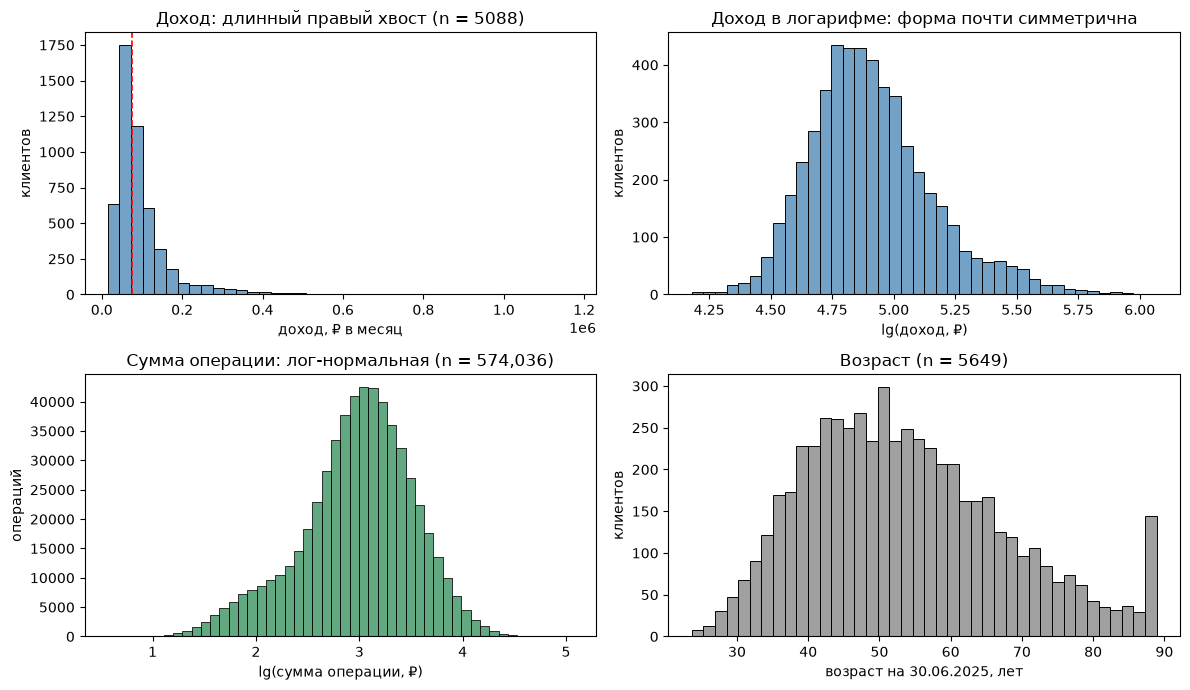

In [34]:
income = df_clients["monthly_income"].dropna()
age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

sns.histplot(income, bins=40, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(income.median(), color="red", ls="--", lw=1.2)
axes[0, 0].set(xlabel="доход, ₽ в месяц", ylabel="клиентов", title=f"Доход: длинный правый хвост (n = {len(income)})")

sns.histplot(np.log10(income), bins=40, ax=axes[0, 1], color="steelblue")
axes[0, 1].set(xlabel="lg(доход, ₽)", ylabel="клиентов", title="Доход в логарифме: форма почти симметрична")

sns.histplot(np.log10(df_ops["amount_rub"]), bins=50, ax=axes[1, 0], color="seagreen")
axes[1, 0].set(xlabel="lg(сумма операции, ₽)", ylabel="операций", title=f"Сумма операции: лог-нормальная (n = {len(df_ops):,})")

sns.histplot(age, bins=40, ax=axes[1, 1], color="gray")
axes[1, 1].set(xlabel="возраст на 30.06.2025, лет", ylabel="клиентов", title=f"Возраст (n = {len(age)})")

plt.tight_layout()
plt.show()


#### Возраст: где именно начинается хвост

Посмотрим на правый хвост возраста отдельно: не «есть ли выбросы», а **на каком значении** плотность перестаёт вести себя как продолжение ряда.


In [35]:
# --- где именно начинается хвост возраста
age = (PERIOD_END - df_clients["birth_date"]).dt.days / 365.25
birth = df_clients["birth_date"]

print("возраст на", PERIOD_END.date(), ":", round(age.min(), 1), "—", round(age.max(), 2))
print("даты рождения:", birth.min().date(), "—", birth.max().date())

tail = np.floor(age.loc[age.ge(80)]).astype(int).value_counts().sort_index()
lam = tail.loc[80:87].mean()
print("\nклиентов в каждом году возраста, 80+:")
print(tail.to_string())
print(f"\nсреднее за 80–87 лет: {lam:.1f} клиентов на год возраста")
print(f"на 88 лет: {tail.loc[88]} — в {tail.loc[88] / lam:.1f} раза больше")

per_month = birth.dt.to_period("M").value_counts().sort_index().loc["1936-07":"1938-06"]
print("\nклиентов по месяцу рождения, последние два года перед обрывом:")
print(per_month.to_string())
print(f"\nплотность до 1937-08: {per_month.loc['1936-08':'1937-07'].mean():.1f} клиентов в месяц; после 1937-08: {per_month.loc['1937-08':].mean():.1f}")

# --- кто эти люди: профиль группы 88+ против соседних
age_by_id = pd.Series(age.values, index=df_clients["client_id"].values)
txn_ok = df_transactions.loc[
    df_transactions["status"].eq("успешно") & df_transactions["client_id"].isin(df_clients["client_id"])
]
ops = txn_ok.groupby("client_id").size()

activity = df_clients[["client_id", "has_mobile_app", "monthly_income"]].assign(
    возраст=age.values,
    операций=lambda d: d["client_id"].map(ops).fillna(0),
    группа=lambda d: pd.cut(d["возраст"], [23, 70, 80, 85, 88, 89], right=False),
)
profile = activity.groupby("группа", observed=True).agg(
    клиентов=("client_id", "size"),
    с_операциями=("операций", lambda s: int(s.gt(0).sum())),
    медиана_операций=("операций", "median"),
    приложение=("has_mobile_app", lambda s: s.eq("Да").mean() * 100),
    доход=("monthly_income", lambda s: s.where(s.gt(0)).median()),
)
profile.columns = ["клиентов", "с операциями", "медиана операций", "приложение, %", "доход, медиана ₽"]
print("\nпрофиль по возрастным группам:")
print(profile.round(1).to_string())

old = age.ge(88)
print(f"\n88+: {int(old.sum())} клиентов, это {old.mean():.1%} базы")
print("пол:", df_clients.loc[old, "gender"].value_counts().to_dict())
print("приложение установлено:", int(df_clients.loc[old, "has_mobile_app"].eq("Да").sum()), "из", int(old.sum()))
print("возраст открытия карты, лет:",
      (df_clients.loc[old, "card_open_date"] - birth.loc[old]).dt.days.div(365.25)
      .describe()[["min", "50%", "max"]].round(1).to_dict())
print("клиентов без единой операции:", int(ops.reindex(df_clients.loc[old, "client_id"]).isna().sum()))
print("операций на клиента, медиана:", int(ops.reindex(df_clients.loc[old, "client_id"]).median()))


возраст на 2025-06-30 : 23.6 — 88.93
даты рождения: 1936-07-26 — 2001-11-09

клиентов в каждом году возраста, 80+:
birth_date
80     24
81     17
82     23
83     23
84     19
85     19
86     21
87     29
88    121

среднее за 80–87 лет: 21.9 клиентов на год возраста
на 88 лет: 121 — в 5.5 раза больше

клиентов по месяцу рождения, последние два года перед обрывом:
birth_date
1936-07     1
1936-08    14
1936-09     5
1936-10    17
1936-11     7
1936-12    12
1937-01    14
1937-02     6
1937-03    18
1937-04     6
1937-05     9
1937-06    12
1937-07    11
1937-08     4
1937-10     1
1937-11     1
1937-12     1
1938-01     3
1938-02     1
1938-03     3
1938-04     1
1938-05     2
1938-06     1
Freq: M

плотность до 1937-08: 10.9 клиентов в месяц; после 1937-08: 1.8

профиль по возрастным группам:
          клиентов  с операциями  медиана операций  приложение, %  доход, медиана ₽
группа                                                                             
[23, 70)      4883        

**Где начинается выброс: на 88.0 лет.** Не «примерно в старости», а на конкретном значении, и проверяется это тремя независимыми способами.

1. **Скачок плотности в годовом разрезе.** 80 лет — 24 клиента, 81 — 17, 82 — 23, 83 — 23, 84 — 19, 85 — 19, 86 — 21, 87 — 29, а 88 — **121**. Среднее за 80–87 равно 21.9, то есть последний год в 5.5 раза плотнее тренда; 
2. **Ступенька в месячном разрезе.** До августа 1937 года — 10.9 клиентов на месяц рождения, после — 1.8. Граница попадает ровно между июлем 1937 (11 клиентов) и августом 1937 (4), то есть на возраст 88.0.
3. **Жёсткий обрыв сверху.** Самый старый клиент — 88.93 года (родился 1936-07-26), и **старше нет ни одного человека**, хотя база — 5649 клиентов. Если бы хвост был естественным, за 121 клиентом на 88 годах стояли бы единицы на 89–95.

Отсюда механика: это не несколько невозможных возрастов (никаких 150 лет в данных нет), а **срез сверху с уплотнением последнего года**. Возраст выше границы не удалён, а сжат в последний год, поэтому «88» здесь читается как «88 и, возможно, больше». 

**Кто эти 121 человек.** Профиль правдоподобный, а не битые строки: пол 64 М / 57 Ж, приложение установлено у 27 из 121 (22.3% против 65.6% у клиентов до 70), медиана 58 операций против 91 у остальных, **ни одного клиента без операций**, карта открыта в возрасте 79.4–88.6 лет (медиана 83.5). Медиана дохода 92 600 ₽ — самая высокая по группам, но это связано с общим ростом дохода с возрастом в этих данных, а не с аномалией группы.

**Решение: не удалять, но перестать считать возраст числом на этом участке.** Удаление 121 клиента (2.1% базы) вырезало бы самую пожилую часть аудитории и ничего не исправило бы: истинный возраст этих людей неизвестен, он лишь «не меньше 88». Поэтому:

- возраст использовать категориями с открытым верхним интервалом (… 85–87, 88+), а не точками;
- не считать среднее, медиану и перцентили возраста по группе 88+ осмысленными;
- не строить правила кампании на пороге внутри последнего года («ровно 88 лет», «старше 88.5») — такой порог отделяет не людей, а артефакт сжатия;
- там, где числовой возраст всё же нужен, обрезать его сверху (`clip(upper=88)`) и оговаривать это в тексте.

Практический вывод для 5.1: остальные три признака (доход, сумма операции, число операций) описываются медианой и IQR спокойно, а по возрасту верхний хвост нужно держать в голове — именно из-за него «пожилая группа» в данных не является выборкой из реальных 88-летних.


**Меры центра и разброса — медиана и IQR, а не среднее и стандартное отклонение.** Доход и сумма операции распределены с длинным правым хвостом: у дохода среднее 98 953 ₽ против медианы 75 800 ₽ (выше на 31%), у суммы операции 1 866 ₽ против 1 066 ₽ (выше на 75%). В таких распределениях среднее сдвигается несколькими крупными значениями и перестаёт описывать типичного клиента, а стандартное отклонение — типичный разброс. Поэтому в таблице есть и медиана, и IQR, и квантили 5/95: они устойчивы к хвосту и не требуют ничего удалять.

Возраст — единственный признак без длинного правого хвоста: медиана 51.9 года, IQR 19.4, диапазон 23.6–88.9, среднее и медиана почти совпадают. Но дефект у него есть, только другого рода — срез сверху на 88 годах с уплотнением последнего года (разобран выше). Медиану и IQR он не портит, а вот точные значения возраста в группе 88+ использовать нельзя.

Число операций на клиента за 18 месяцев: медиана 88, IQR 85, максимум 608. Разрыв между медианой и максимумом почти семикратный, то есть «средний клиент» — плохое понятие, и любой показатель дальше надо считать в расчёте на клиента.


### 5.2. Частотные характеристики категориальных признаков

In [36]:
def frequency_table(series, name):
    table = series.value_counts(dropna=False).rename("значений").to_frame()
    table["доля, %"] = (table["значений"] / len(series) * 100).round(1)
    table.index.name = name
    return table


print("клиенты, знаменатель =", len(df_clients))
for column in ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "marketing_opt_in", "income_source", "gender"]:
    print(f"\n{column}")
    print(frequency_table(df_clients[column], column).to_string())

print("\n\nоперации, знаменатель =", len(df_transactions))
for column in ["channel", "category", "status", "currency"]:
    print(f"\n{column}")
    print(frequency_table(df_transactions[column], column).to_string())


клиенты, знаменатель = 5649

segment
             значений  доля, %
segment                       
Массовый         2835     50.2
Зарплатный       1598     28.3
Премиальный       972     17.2
Private           244      4.3

loyalty_tier
              значений  доля, %
loyalty_tier                   
Базовый           2843     50.3
Серебро           1535     27.2
Золото             954     16.9
Платина            317      5.6

card_type
             значений  доля, %
card_type                     
Дебетовая        3905     69.1
Кредитная        1218     21.6
Премиальная       526      9.3

city
                 значений  доля, %
city                              
Москва               1651     29.2
Санкт-Петербург       998     17.7
Казань                907     16.1
Новосибирск           701     12.4
Нижний Новгород       697     12.3
Екатеринбург          695     12.3

has_mobile_app
                значений  доля, %
has_mobile_app                   
Да                  3460     61.2
Н

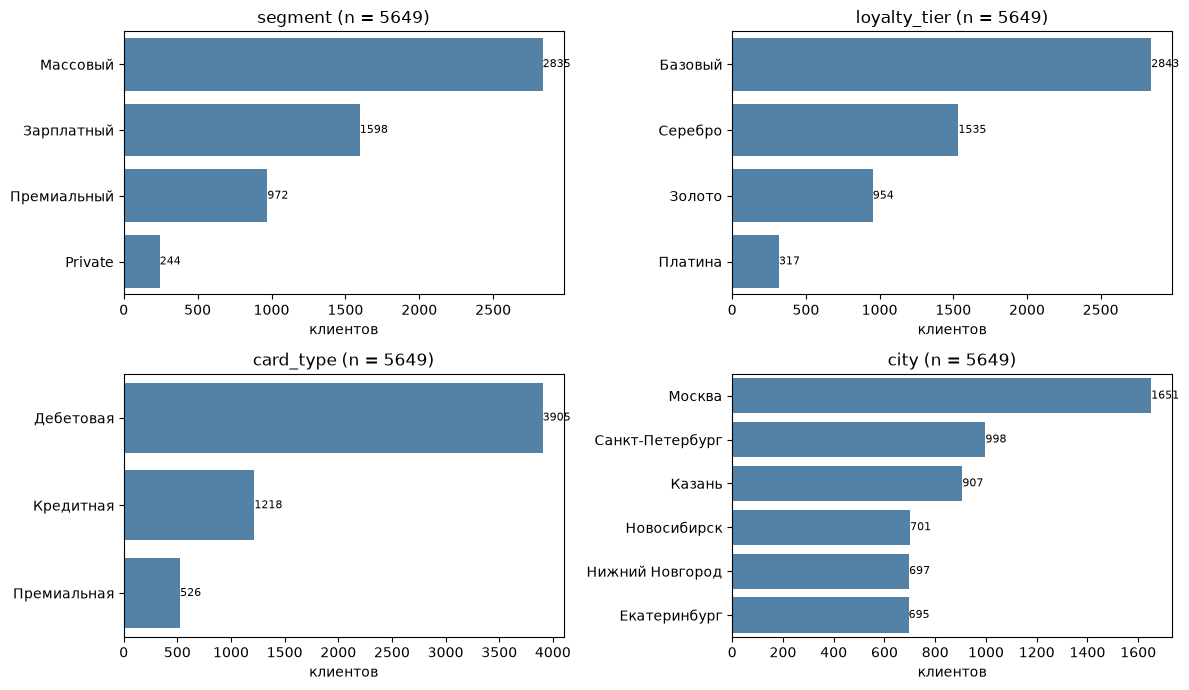

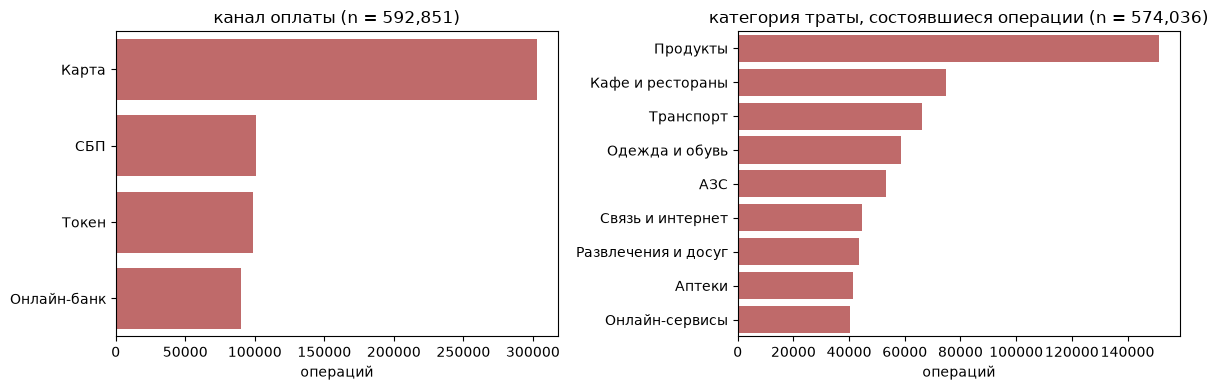

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, column in zip(axes.ravel(), ["segment", "loyalty_tier", "card_type", "city"]):
    order = df_clients[column].value_counts().index
    sns.countplot(data=df_clients, y=column, order=order, ax=ax, color="steelblue")
    ax.set(xlabel="клиентов", ylabel="", title=f"{column} (n = {len(df_clients)})")
    ax.bar_label(ax.containers[0], fontsize=8)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_transactions, y="channel", order=df_transactions["channel"].value_counts().index, ax=axes[0], color="indianred")
axes[0].set(xlabel="операций", ylabel="", title=f"канал оплаты (n = {len(df_transactions):,})")

sns.countplot(data=df_ops, y="category", order=df_ops["category"].value_counts().index, ax=axes[1], color="indianred")
axes[1].set(xlabel="операций", ylabel="", title=f"категория траты, состоявшиеся операции (n = {len(df_ops):,})")

plt.tight_layout()
plt.show()


**Что видно в частотах.** База однородна по полу (50.7% женщин, 49.3% мужчин) и сильно неоднородна по сегменту: массовый — половина клиентов (50.2%), Private — 4.3%. Поэтому любое утверждение «в среднем по банку» фактически будет утверждением про массовый сегмент, и это надо помнить во всех разрезах.

Каналы: «Карта» 51.1%, остальные три делят вторую половину почти поровну — СБП 17.0%, Токен 16.7%, Онлайн-банк 15.2%. Категории: «Продукты» 26.3% — самая частая, далее «Кафе и рестораны» 13.0% и «Транспорт» 11.5%, редкая — «Онлайн-сервисы» 7.0%.

Статусы: 96.8% операций состоялись, 2.0% отклонены, 1.2% возвраты. Знаменатель здесь 592 851 — это операции, а не клиенты; доля отклонённых от числа клиентов не считается.

Согласие на коммуникацию дали 88.1% клиентов, то есть ограничение «только с согласием» отсекает около 12% базы независимо от сегмента.


### 5.3. Динамика по месяцам

In [38]:
month = df_ops["txn_datetime"].dt.to_period("M")
df_ops_by_month = df_ops.groupby(month)

monthly = pd.DataFrame(
    {
        "операций": df_ops_by_month.size(),
        "клиентов": df_ops_by_month["client_id"].nunique(),
        "медианный чек, ₽": df_ops_by_month["amount_rub"].median().round(0),
        "доля «Карта», %": (df_ops_by_month["channel"].apply(lambda s: s.eq("Карта").mean() * 100)).round(1),
    }
)
monthly.index = monthly.index.astype(str)
monthly.index.name = "месяц"
monthly


,операций,клиентов,"медианный чек, ₽","доля «Карта», %"
месяц,,,,
2024-01,23969,4643,1073.0,53.1
2024-02,30288,4734,1073.0,52.8
2024-03,34863,4768,1073.0,52.9
2024-04,33728,4754,1069.0,53.3
2024-05,31184,4762,1091.0,53.1
2024-06,33599,4763,1088.0,53.2
2024-07,34374,4784,1078.0,52.7
2024-08,35700,4857,1071.0,53.3
2024-09,33973,4914,1076.0,53.0


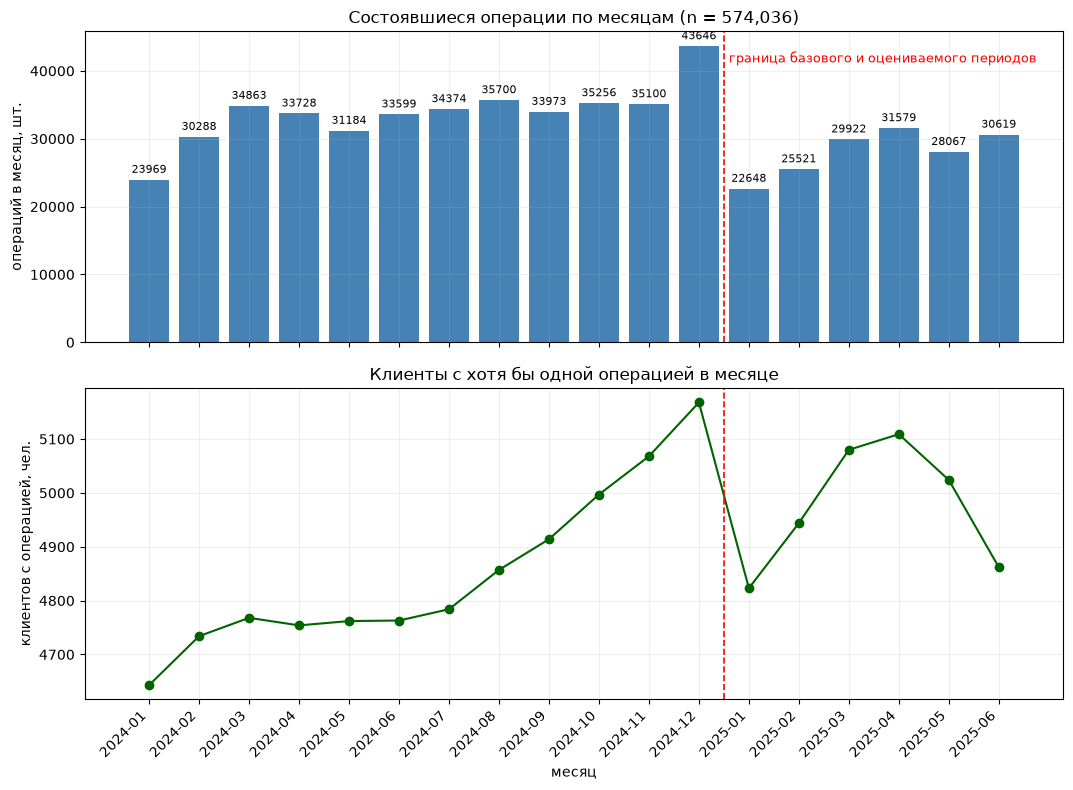

январь 2024: четыре дня с максимумом операций
 день месяца день недели  операций
           5          пт      1206
           6          сб      1543
          20          сб      1532
          21          вс      1543
медиана по дню месяца: 669 операций


In [39]:
x = np.arange(len(monthly))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

bars = axes[0].bar(x, monthly["операций"], color="steelblue")
axes[0].bar_label(bars, padding=3, fontsize=8)

axes[0].set(ylabel="операций в месяц, шт.", title=f"Состоявшиеся операции по месяцам (n = {len(df_ops):,})")

axes[1].plot(x, monthly["клиентов"], marker="o", color="darkgreen")
axes[1].set(ylabel="клиентов с операцией, чел.", xlabel="месяц", title="Клиенты с хотя бы одной операцией в месяце")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(monthly.index, rotation=45, ha="right")
    ax.axvline(11.5, color="red", ls="--", lw=1.2)
    ax.grid(alpha=0.2)

axes[0].annotate("граница базового и оцениваемого периодов", xy=(11.6, axes[0].get_ylim()[1] * 0.9), fontsize=9, color="red")

plt.tight_layout()
plt.show()

# --- проверка календарной гипотезы: пики внутри января 2024 по дням месяца
january_24 = df_ops.loc[df_ops["txn_datetime"].dt.to_period("M").astype(str).eq("2024-01")]
by_day = january_24.groupby(january_24["txn_datetime"].dt.day).size()
top_days = by_day.nlargest(4).sort_index()
WEEKDAY_RU = {0: "пн", 1: "вт", 2: "ср", 3: "чт", 4: "пт", 5: "сб", 6: "вс"}

print("январь 2024: четыре дня с максимумом операций")
print(
    pd.DataFrame(
        {
            "день месяца": top_days.index.astype(int),
            "день недели": [WEEKDAY_RU[pd.Timestamp(2024, 1, int(day)).day_of_week] for day in top_days.index],
            "операций": top_days.to_numpy(),
        }
    ).to_string(index=False)
)
print(f"медиана по дню месяца: {by_day.median():.0f} операций")


**Динамика по месяцам операций и клиентов.** Ряд читается только вместе с календарём: максимум — декабрь 2024 (43 646 операций), минимум — январь 2025 (22 648). Январь 2024 тоже низкий (23 969), декабрь высокий, и внутри января 2024 четыре дня дают 1 206–1 543 операции против медианы 669 по месяцу: 5-е (пятница, 1 206), 6-е и 20-е (суббота, 1 543 и 1 532) и 21-е (воскресенье, 1 543). Это сезонность и календарь, а не падение активности; к тому же месяцы различаются числом выходных дней.

Три вещи, которые видны уже на этом уровне и от сезонности не зависят:

1. Число клиентов с хотя бы одной операцией за месяц не падает: 4643 в январе 2024 → 5168 в декабре 2024 → 4862 в июне 2025. Охват держится, меняется интенсивность, а не число людей.
2. Медианный чек снизился: 1069–1091 ₽ в 2024 против 1030–1047 ₽ в 2025 — примерно на 3–5%.
3. Доля не-«Карта» выросла с 46.7–47.6% в 2024 до 50.7–55.3% в 2025: клиенты чаще платят телефоном и через СБП, реже пластиком.

Ограничение, которое из этого следует: окна разной длины (12 и 6 месяцев) и разная сезонность внутри них, поэтому сравнивать суммы «2024 против 2025» напрямую нельзя — только в расчёте на месяц и с поправкой на календарь.


In [40]:
# --- полнота выгрузки: непрерывность txn_id по месяцам
RAW = pd.read_csv(RAW_TXN_PATH, encoding="cp1251", sep=";", dtype={"txn_id": "Int64", "txn_datetime": "string"})
RAW["dt"] = pd.to_datetime(RAW["txn_datetime"], errors="coerce", format="mixed")
RAW["month"] = RAW["dt"].dt.to_period("M").astype(str)

TAIL = RAW.loc[RAW["txn_id"] >= 990000]
MAIN = (
    RAW.loc[RAW["txn_id"] < 990000]
    .drop_duplicates(subset=["txn_id"])
    .sort_values("txn_id")
    .reset_index(drop=True)
)

step = np.diff(MAIN["txn_id"].astype("int64").to_numpy())
gap = np.where(step > 1)[0]
missing = (
    pd.Series(step[gap] - 1, index=MAIN["month"].to_numpy()[gap])
    .groupby(level=0)
    .sum()
    .reindex(sorted(RAW["month"].unique()), fill_value=0)
)

print(
    f"основной блок: {len(MAIN)} уникальных txn_id, {MAIN['txn_id'].min()}–{MAIN['txn_id'].max()}, "
    f"даты {MAIN['dt'].min().date()} … {MAIN['dt'].max().date()}"
)
print(
    f"довесок id >= 990000: {len(TAIL)} строк, {TAIL['txn_id'].min()}–{TAIL['txn_id'].max()}, "
    f"даты {TAIL['dt'].min().date()} … {TAIL['dt'].max().date()}, "
    f"вне окна {int((~TAIL['dt'].dt.normalize().between(PERIOD_START, PERIOD_END)).sum())}"
)
print(f"\nпропущено txn_id внутри основного блока: {int(missing.sum())}")
print(missing[missing > 0].to_string())

win = MAIN.loc[MAIN["dt"].dt.normalize().between(PERIOD_START, PERIOD_END)].copy()
base_share = win.loc[win["month"].isin(["2025-01", "2025-04", "2025-05", "2025-06"]), "channel"].value_counts(
    normalize=True
)

rows = []
for month in ["2025-02", "2025-03"]:
    part = win.loc[win["month"] == month]
    full = len(part) + int(missing.loc[month])
    print(
        f"\n{month}: в файле {len(part)} строк, ожидалось {full} "
        f"(не хватает {int(missing.loc[month])}, {missing.loc[month] / full:.1%})"
    )
    for channel, share in base_share.items():
        fact = int(part["channel"].eq(channel).sum())
        rows.append(
            {
                "месяц": month,
                "канал": channel,
                "факт": fact,
                "ожидание": round(full * share),
                "отклонение": round(fact - full * share),
                "отклонение, %": round((fact / (full * share) - 1) * 100, 1),
            }
        )

pd.DataFrame(rows)

основной блок: 623556 уникальных txn_id, 100001–728518, даты 2024-01-01 … 2025-06-30
довесок id >= 990000: 220 строк, 990001–990220, даты 2023-12-10 … 2026-08-01, вне окна 85

пропущено txn_id внутри основного блока: 4962
2025-02    2325
2025-03    2637

2025-02: в файле 27183 строк, ожидалось 29508 (не хватает 2325, 7.9%)

2025-03: в файле 31409 строк, ожидалось 34046 (не хватает 2637, 7.7%)


,месяц,канал,факт,ожидание,отклонение,"отклонение, %"
0,2025-02,Карта,13410,13373,37,0.3
1,2025-02,Токен,6393,6532,-139,-2.1
2,2025-02,СБП,2903,5201,-2298,-44.2
3,2025-02,Онлайн-банк,4477,4402,75,1.7
4,2025-03,Карта,15430,15429,1,0.0
5,2025-03,Токен,7500,7536,-36,-0.5
6,2025-03,СБП,3328,6001,-2673,-44.5
7,2025-03,Онлайн-банк,5151,5079,72,1.4


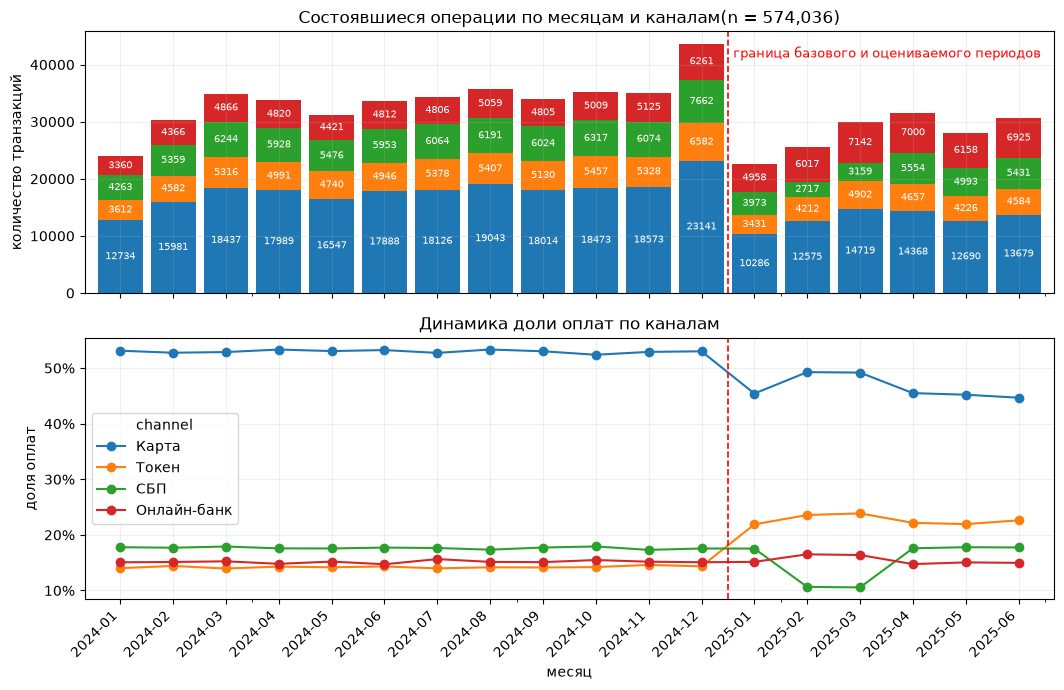

In [41]:
# --- Изменение активности по каналам
ops_by_chanel = df_ops_by_month['channel']
shares = ops_by_chanel.value_counts(normalize=True).unstack(fill_value=0)
abs_counts = ops_by_chanel.value_counts().unstack(fill_value=0)
shares.index = shares.index.astype(str) 
abs_counts.index = abs_counts.index.astype(str) 
shares = shares[shares.mean().sort_values(ascending=False).index]

x = np.arange(len(shares))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

abs_counts.plot.bar(stacked=True, width=0.85, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, label_type="center", fontsize=7, color="white")

axes[0].set(ylabel="количество транзакций", title=f"Состоявшиеся операции по месяцам и каналам(n = {len(df_ops):,})")

shares.plot.line(marker="o", ax=axes[1]) 
axes[1].set(ylabel="доля оплат", xlabel="месяц", title="Динамика доли оплат по каналам")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(shares.index, rotation=45, ha="right")
    ax.axvline(11.5, color="red", ls="--", lw=1.2)
    ax.grid(alpha=0.2)

axes[0].annotate(
    "граница базового и оцениваемого периодов",
    xy=(11.6, axes[0].get_ylim()[1] * 0.9),
    fontsize=9, color="red",
)
axes[0].legend_.remove()
plt.tight_layout()
plt.show()


**Что видим:** Доли оплат по различным источникам почти не меняется за 2024 год, но дальше видим сильную просадку оплат по картам и подъем в опалатах токенов, видимо это просто переток клиентов на другой метод оплаты. Самая странная аномалия видна в оплате СБП, там видна просадка доли оплаты в марте и феврале, при этом в остальном периоде он стабильный. Есть подозрение. что это как раз те транзакции которые были определены в пункте 3.0 как отсутствующие.

Выровняем отсутствующие операции по СБП на долю которая отсутствовала и проверим данные

In [42]:
# --- Проверяем гипотезу о потерянных операциях в СБП
SKIPPED_SHARE_BY_MONTH.index = SKIPPED_SHARE_BY_MONTH.index.astype(str)
ops_by_month = df_ops_by_month['txn_id'].count()
ops_by_month.index = ops_by_month.index.astype(str)

# недостача задана долей месяца, недостающие id распределены по статусам как и остальные строки,
# поэтому переводим её в успешные операции того же месяца (а не берём долю от всех статусов)
missed_ops = (ops_by_month * SKIPPED_SHARE_BY_MONTH / (1 - SKIPPED_SHARE_BY_MONTH)).round().astype(int)
print('Добавлено операций в СБП (оценка):')
print(missed_ops[missed_ops > 0])

# восстановленный канал собираем в отдельный объект: abs_counts не меняем, чтобы ячейка
# оставалась идемпотентной, а исходные данные не «дописывались»
abs_counts_restored = df_ops_by_month['channel'].value_counts().unstack(fill_value=0)
abs_counts_restored.index = abs_counts_restored.index.astype(str)
abs_counts_restored = abs_counts_restored[abs_counts.columns]
abs_counts_restored['СБП'] = abs_counts_restored['СБП'] + missed_ops

Добавлено операций в СБП (оценка):
txn_datetime
2025-02    2183
2025-03    2511
dtype: int64


In [43]:
abs_counts_restored.div(abs_counts_restored.sum(axis=1), axis=0).round(4)

channel,Карта,Онлайн-банк,СБП,Токен
txn_datetime,,,,
2024-01,0.5313,0.1507,0.1779,0.1402
2024-02,0.5276,0.1513,0.1769,0.1441
2024-03,0.5288,0.1525,0.1791,0.1396
2024-04,0.5334,0.1480,0.1758,0.1429
2024-05,0.5306,0.1520,0.1756,0.1418
2024-06,0.5324,0.1472,0.1772,0.1432
2024-07,0.5273,0.1565,0.1764,0.1398
2024-08,0.5334,0.1515,0.1734,0.1417
2024-09,0.5302,0.1510,0.1773,0.1414


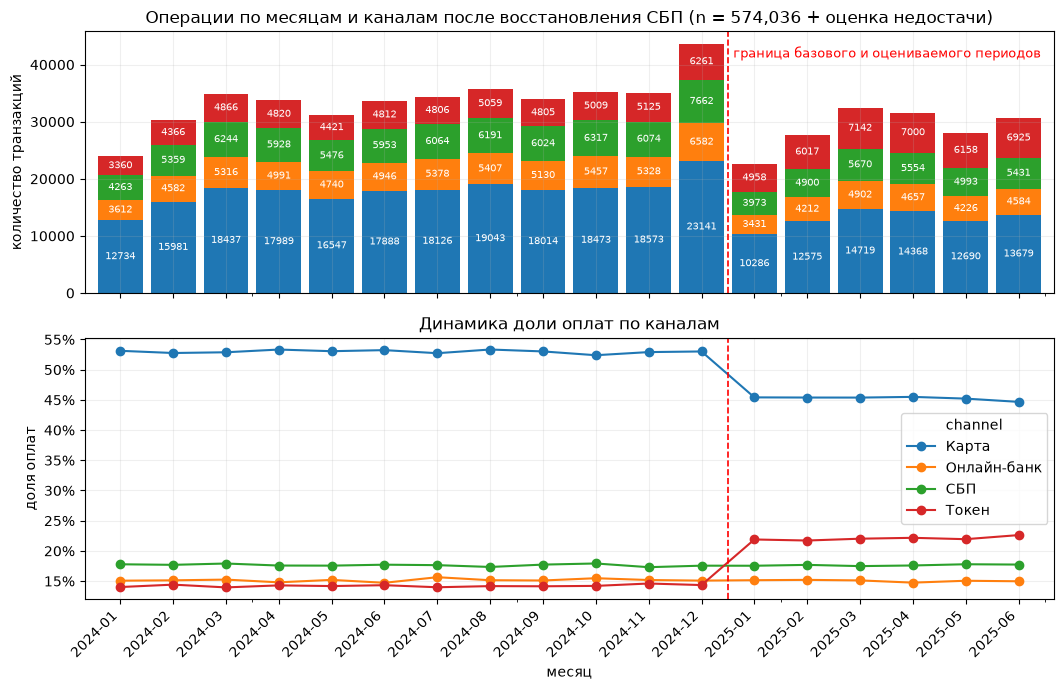

In [44]:
# --- графики после восстановления канала СБП (оценка недостачи, в данные не попадает)
shares = abs_counts_restored.div(abs_counts_restored.sum(axis=1), axis=0)

x = np.arange(len(shares))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

abs_counts_restored.plot.bar(stacked=True, width=0.85, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, label_type="center", fontsize=7, color="white")

axes[0].set(
    ylabel="количество транзакций",
    title=f"Операции по месяцам и каналам после восстановления СБП (n = {len(df_ops):,} + оценка недостачи)",
)

shares.plot.line(marker="o", ax=axes[1]) 
axes[1].set(ylabel="доля оплат", xlabel="месяц", title="Динамика доли оплат по каналам")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(shares.index, rotation=45, ha="right")
    ax.axvline(11.5, color="red", ls="--", lw=1.2)
    ax.grid(alpha=0.2)

axes[0].annotate(
    "граница базового и оцениваемого периодов",
    xy=(11.6, axes[0].get_ylim()[1] * 0.9),
    fontsize=9, color="red",
)
axes[0].legend_.remove()
plt.tight_layout()
plt.show()

In [45]:
# --- схожесть активности в первых полугодиях: 2024 против 2025
H1_24 = [f"2024-0{m}" for m in range(1, 7)]
H1_25 = [f"2025-0{m}" for m in range(1, 7)]
LABELS = ["янв", "фев", "мар", "апр", "май", "июн"]

# то же, но в определении метрики: без СБП (в фев–мар 2025 в этом канале потеряны строки)
df_ops_no_sbp = df_ops.loc[df_ops["channel"] != "СБП"]
month_no_sbp = df_ops_no_sbp["txn_datetime"].dt.to_period("M")
group_no_sbp = df_ops_no_sbp.groupby(month_no_sbp)
monthly_no_sbp = pd.DataFrame({"операций": group_no_sbp.size(), "клиентов": group_no_sbp["client_id"].nunique()})
monthly_no_sbp.index = monthly_no_sbp.index.astype(str)

opc = monthly["операций"] / monthly["клиентов"]
opc_no_sbp = monthly_no_sbp["операций"] / monthly_no_sbp["клиентов"]
a, b = opc.loc[H1_24].to_numpy(), opc.loc[H1_25].to_numpy()
a_n, b_n = opc_no_sbp.loc[H1_24].to_numpy(), opc_no_sbp.loc[H1_25].to_numpy()

pd.DataFrame(
    {
        "2024, все каналы": a.round(2),
        "2025, все каналы": b.round(2),
        "изм. все каналы, %": ((b / a - 1) * 100).round(1),
        "2024, без СБП": a_n.round(2),
        "2025, без СБП": b_n.round(2),
        "изм. без СБП, %": ((b_n / a_n - 1) * 100).round(1),
    },
    index=LABELS,
)

,"2024, все каналы","2025, все каналы","изм. все каналы, %","2024, без СБП","2025, без СБП","изм. без СБП, %"
янв,5.16,4.70,-9.0,4.45,4.10,-7.7
фев,6.40,5.16,-19.3,5.43,4.78,-12.0
мар,7.31,5.89,-19.4,6.19,5.46,-11.8
апр,7.09,6.18,-12.9,6.02,5.35,-11.2
май,6.55,5.59,-14.7,5.58,4.85,-13.1
июн,7.05,6.30,-10.7,5.99,5.44,-9.2


**Вывод по 5.3: потерянные транзакции.**

Пропуски в файле есть в двух месяцах из восемнадцати: февраль 2025 — 2 325 отсутствующих `txn_id` (7.9% месяца), март — 2 637 (7.7%); во всех остальных месяцах ключи идут подряд, без единого разрыва. (В разделе 3.0 тот же март даёт 2 636 — расхождение в одну строку возникает из-за привязки недостающего `txn_id` к границе месяца: там недостача считается как разность «ожидание − факт», здесь — по разрывам в последовательности ключей; на вывод это не влияет.) Недостача целиком ложится на СБП: после возврата в канал 2 183 и 2 511 операции (оценка недостачи в успешных операциях месяца) его доля становится 17.7% и 17.5% против 17.5–17.8% в остальных месяцах 2025 года, а доля «Карты» — 45.4% и 45.4% вместо 49.3% и 49.2% до выравнивания, её размах по 2025 году сжимается с 4.6 до 0.8 пп. Просадка февраля–марта — дефект выгрузки, а не поведение клиентов. Также после выравнивания видно, что доля СБП и Онлайн-банка на всем периоде остается стабильной, меняется только переход клиентов из оплаты картой в оплату токеном.

Восстановление здесь носит характер оценки и в данные не попадает: строки не дописываются, «достроенный» канал живёт в отдельной таблице. Всю эту информацию стоит учесть при выборе метрики активности, т.к. из-за потери части транзакций по СБП мы можем получить скошенные количественные данные.


### 5.4. Разрезы и связи между признаками

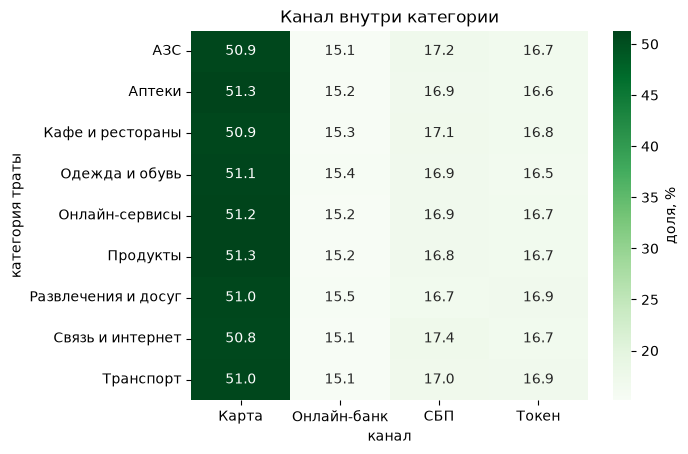

In [46]:
channel_share = pd.crosstab(df_ops["category"], df_ops["channel"], normalize="index").mul(100)
ax = sns.heatmap(channel_share, annot=True, fmt=".1f", cmap="Greens", cbar_kws={"label": "доля, %"})
ax.set(xlabel="канал", ylabel="категория траты", title="Канал внутри категории");

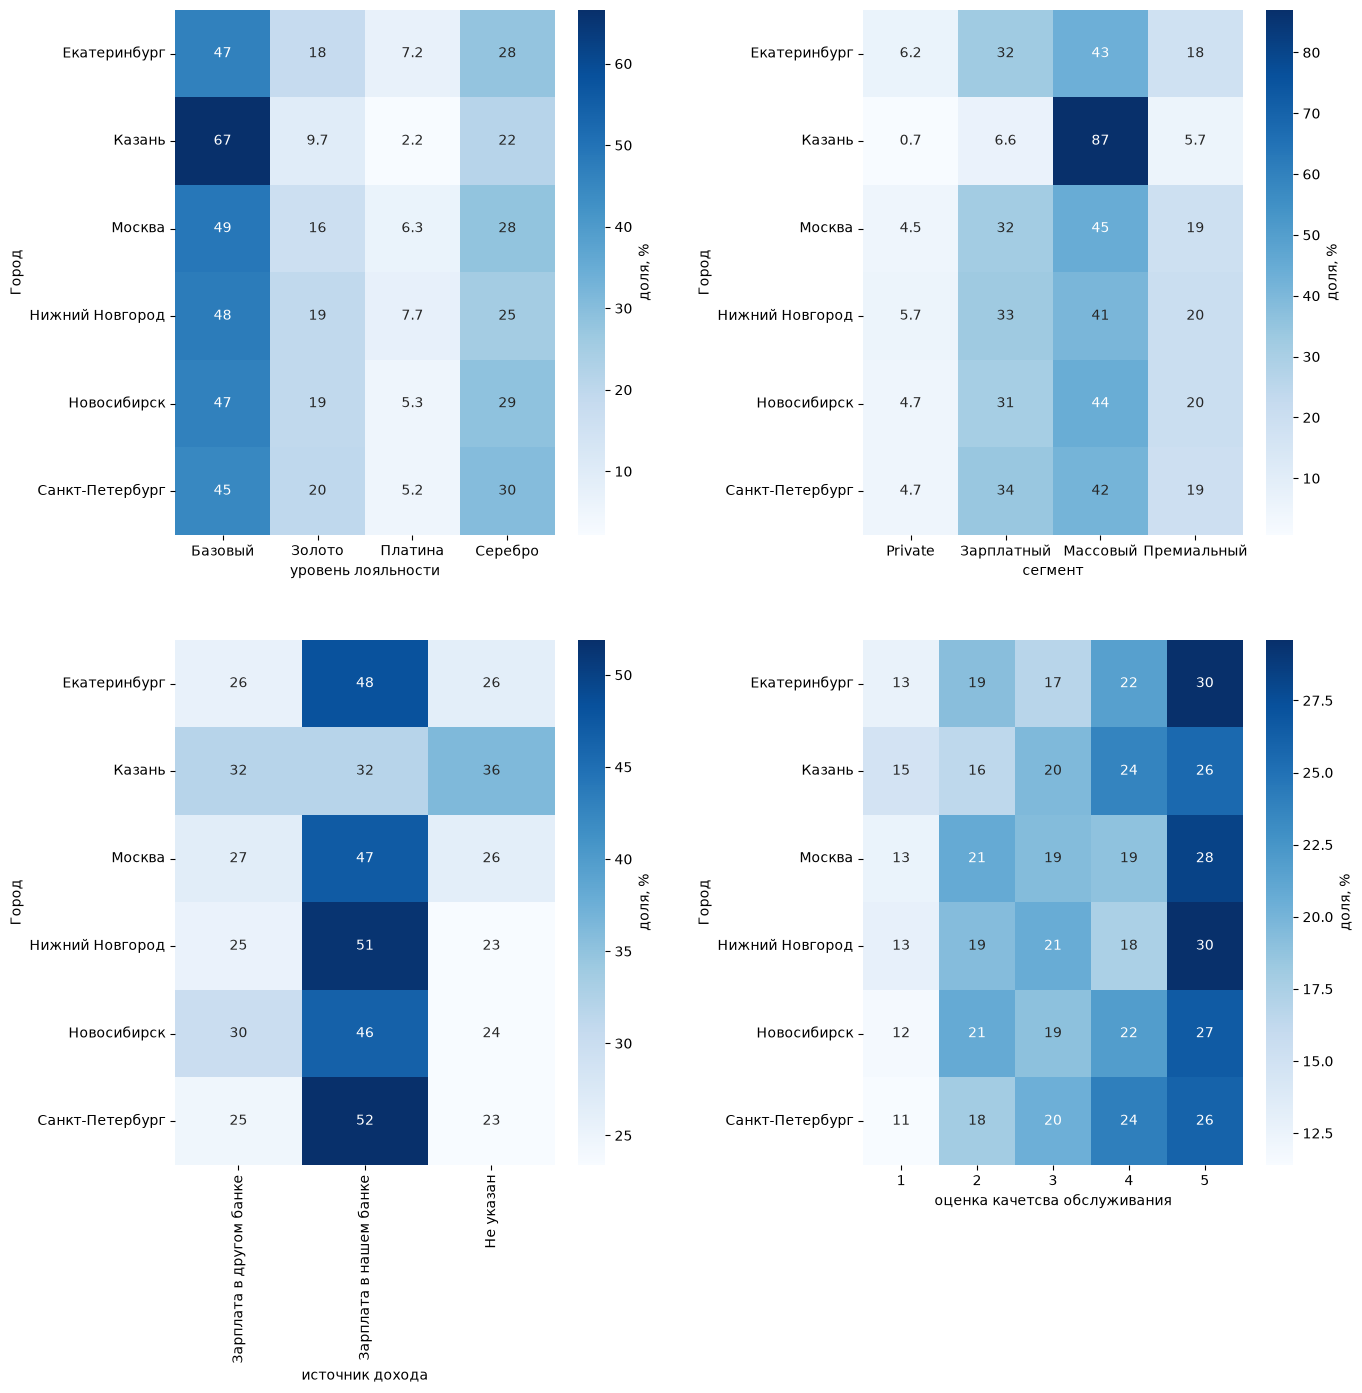

In [47]:
# --- разрез по городам
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
fig.subplots_adjust(hspace=0.2, wspace=0.45)
city_to_cat = {'loyalty_tier': 'уровень лояльности', 
               'segment': 'сегмент', 
               'income_source':'источник дохода', 
               'satisfaction_score': 'оценка качетсва обслуживания'}

for ax, cat, ru_cat in zip(axes.flat, city_to_cat.keys(), city_to_cat.values()):
    sns.heatmap(
        pd.crosstab(df_clients["city"], df_clients[cat], normalize="index").mul(100).round(1),
        annot=True, cmap="Blues",
        cbar_kws={"label": "доля, %"},
        ax=ax,
    )
    ax.set(xlabel=ru_cat, ylabel="Город")

Text(0, 0.5, 'Распределение дохода')

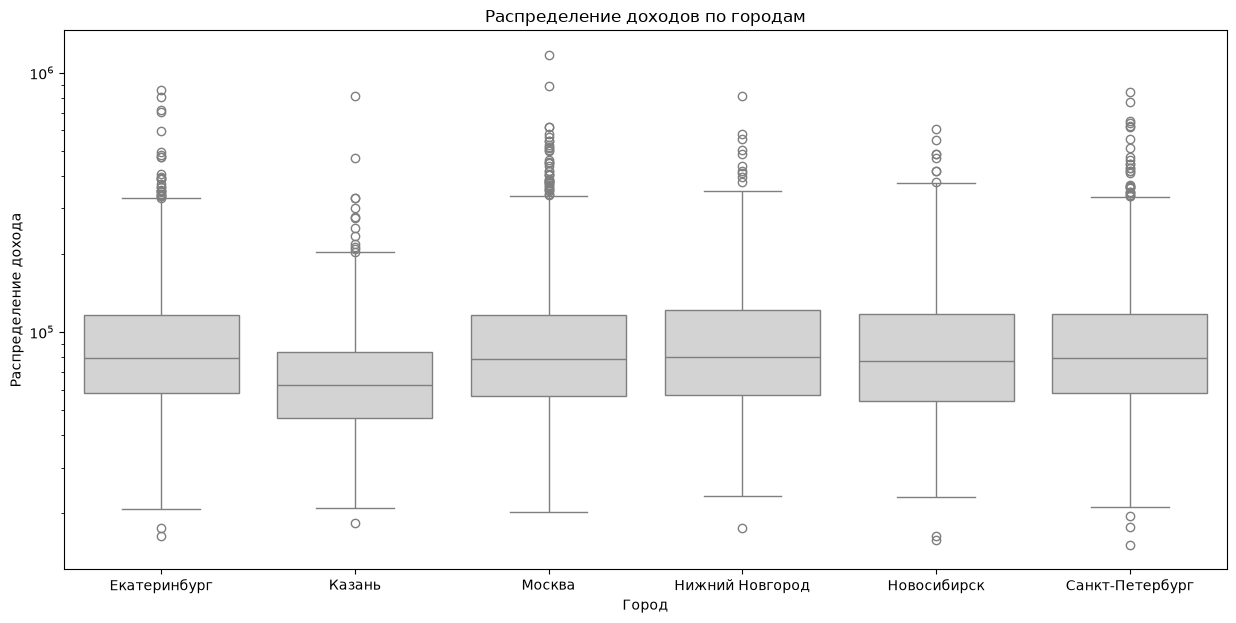

In [48]:
plt.figure(figsize = (15, 7))
sns.boxplot(data=df_clients, x="city", y="monthly_income", log_scale=True, color="lightgray", )
plt.title('Распределение доходов по городам')
plt.xlabel('Город')
plt.ylabel("Распределение дохода")

**Признаки по городам** в целом распределены одинаково кроме Казани, в ней больше всего базового типа лояльности и массового сектора, более равномерно распределен источник дохода, но при этом пороги распределения дохода ниже чем в других городах.

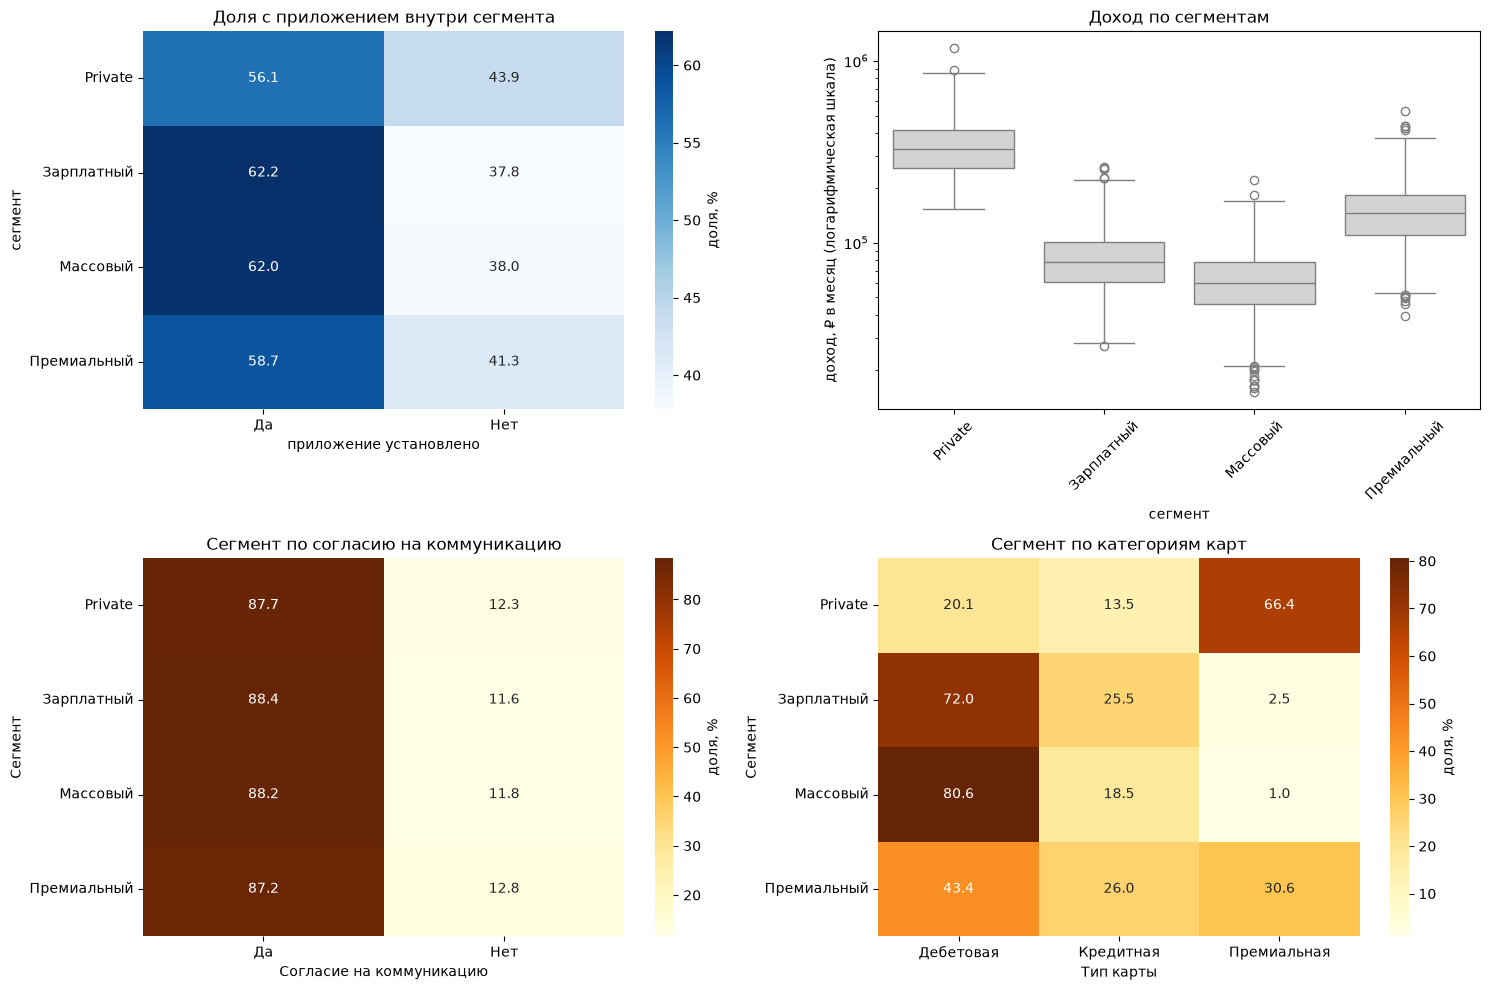

профиль сегментов, знаменатель — клиенты сегмента


,клиентов,"доход, медиана ₽","приложение «Да», %","согласие «Да», %","карта «Дебетовая», %","карта «Премиальная», %"
segment,,,,,,
Массовый,2835,60000.0,62.0,88.2,80.6,1.0
Зарплатный,1598,78000.0,62.2,88.4,72.0,2.5
Премиальный,972,145600.0,58.7,87.2,43.4,30.6
Private,244,327600.0,56.1,87.7,20.1,66.4


In [49]:
# --- Срезы по сегментам
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

share_app = pd.crosstab(df_clients["segment"], df_clients["has_mobile_app"], normalize="index").mul(100)
sns.heatmap(share_app, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "доля, %"}, ax=axes[0, 0])
axes[0, 0].set(xlabel="приложение установлено", ylabel="сегмент", title="Доля с приложением внутри сегмента")

sns.boxplot(data=df_clients, x="segment", y="monthly_income", ax=axes[0, 1], log_scale=True, color="lightgray")
axes[0, 1].set(xlabel="сегмент", ylabel="доход, ₽ в месяц (логарифмическая шкала)", title="Доход по сегментам")
axes[0, 1].tick_params(axis="x", rotation=45)

segment_in_market_opt = pd.crosstab(df_clients["segment"], df_clients["marketing_opt_in"], normalize="index").mul(100).round(1)
sns.heatmap(segment_in_market_opt, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "доля, %"}, ax=axes[1, 0])
axes[1, 0].set(xlabel="Согласие на коммуникацию", ylabel="Сегмент", title="Сегмент по согласию на коммуникацию")

card_in_segment = pd.crosstab(df_clients["segment"], df_clients["card_type"], normalize="index").mul(100).round(1)
sns.heatmap(card_in_segment, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "доля, %"}, ax=axes[1, 1])
axes[1, 1].set(xlabel="Тип карты", ylabel="Сегмент", title="Сегмент по категориям карт")

plt.tight_layout()
plt.show()

# --- те же числа в табличной форме, чтобы их можно было сверить с текстом выше
segment_profile = df_clients.groupby("segment", observed=True).agg(
    клиентов=("client_id", "size"),
    доход_медиана=("monthly_income", "median"),
    приложение_Да=("has_mobile_app", lambda s: s.eq("Да").mean() * 100),
    согласие_Да=("marketing_opt_in", lambda s: s.eq("Да").mean() * 100),
    дебетовая=("card_type", lambda s: s.eq("Дебетовая").mean() * 100),
    премиальная=("card_type", lambda s: s.eq("Премиальная").mean() * 100),
)
segment_profile.columns = [
    "клиентов",
    "доход, медиана ₽",
    "приложение «Да», %",
    "согласие «Да», %",
    "карта «Дебетовая», %",
    "карта «Премиальная», %",
]
print("профиль сегментов, знаменатель — клиенты сегмента")
segment_profile.sort_values("доход, медиана ₽").round(1)


**Разрезы.** Сегмент — самый информативный признак, и он связан почти со всем:

- доход: медиана 60 000 ₽ у массового, 78 000 у зарплатного, 145 600 у премиального, 327 600 у Private. Разрыв в 5.5 раза, причём у крайних сегментов не перекрываются даже IQR;
- тип карты: у массового и зарплатного это «Дебетовая» (80.6% и 72.0%), у Private — «Премиальная» (66.4%);
- приложение: доля владельцев почти одинакова — 56.1% у Private против 62.2% у зарплатного, то есть наличие приложения сегменты не различает;
- согласие на коммуникацию: 87.2–88.4% во всех сегментах, тоже не различает.

Пара, где связи нет вовсе, — канал и категория траты: во всех девяти категориях распределение каналов одинаково (≈51% Карта, 17% СБП, 17% Токен, 15% Онлайн-банк). Канал описывает способ оплаты, а не тип покупки, и как признак «кто это» он дублирует сам себя.

Так-же интересная информация была получена по городам: у клиентов в Казани сильнее представлен массовый сегмент и базовый уровень лояльности наряду с меньшим уровне дохода, при анализе активности отдельно стоит проверить этот город.

Вывод для дальнейшего: сегмент, уровень лояльности, тип карты и доход — связанные признаки, их нельзя предъявлять заказчику как независимые причины. Наличие приложения и согласие на коммуникацию от сегмента не зависят, поэтому годятся и как признак группы, и как ограничение кампании.


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

#### Рассчет метрики

В качетсве метрики активности будем брать среднее количество операций клиета за месяц по указанным периодам, возьмем все каналы кроме СБП(причина — потеря 7.9% и 7.7% строк в фев–мар 2025, в остальные месяцы доля канала стабильна 17.5–17.8%). В метрику будем брать клиентов, у которых карта открыта до 2024-01-01 — только у них наблюдаются целиком и базовый период (12 мес.), и оцениваемый (6 мес.). Дальнешие сравнения будет производить по отношению уровня двух годов

Проверка критерия по `card_open_date`: у 680 клиентов приход в банк раньше 2024 года, но текущая карта открыта в 2024-м — это перевыпуск. Их операции начинаются не раньше июля 2024 (до этого ни одной операции), то есть в базовом периоде они действительно не наблюдаемы, и критерий по дате карты никого наблюдаемого не отсекает.

Минимальную активность клиента для включения в отбор определим далее.

Данная метрика нам поможет отследить общую активность клиентов в указанные периоды, но не сможет отследить следующие признаки:

1. Изменение количества потраченных денег при оплате. В случае если клиент стал больше но реше тратить или наоборот, то мы рискуем неверно интерпретировать увиденное.

2. Переток оплаты в разные категории, например переход части оплат из `Продукты` в `Онлайн-сервисы`.

3. Изменения активности на более мелких периодах, мы не сможем отличить падение в конкретном месяце от падения во всем периоде.

In [50]:
# --- Численное обоснование выбора метрики

clients_card_before_24_mask = (df_clients['card_open_date'].dt.date < datetime.date(2024, 1, 1))
before_24_sum = clients_card_before_24_mask.sum()
print(f'Количество клиентов c картой открытой до 2024: {before_24_sum}({(before_24_sum/len(df_clients)):.1%} от {len(df_clients)})')

# --- проверка критерия по card_open_date: перевыпуск карты внутри базового периода
reissue = df_clients["card_open_date"].ge(PERIOD_START) & df_clients["registration_date"].lt(PERIOD_START)
reissue_ops = df_ops.loc[df_ops["client_id"].isin(df_clients.loc[reissue, "client_id"])]
print(
    f"перевыпуск карты (приход в банк до 2024, текущая карта открыта с 2024): {int(reissue.sum())} клиентов; "
    f"их состоявшихся операций: {len(reissue_ops)}, первая {reissue_ops['txn_datetime'].min():%Y-%m-%d}, "
    f"операций до 2024-07-01: {int(reissue_ops['txn_datetime'].lt(pd.Timestamp('2024-07-01')).sum())}"
)

df_ops_bef_24 = df_ops[df_ops['client_id'].isin(df_clients.loc[clients_card_before_24_mask, 'client_id'])]

CLEAN_MONTHS = [1, 4, 5, 6]   # месяцы без дефекта выгрузки в СБП


def window_rate(year: int, months: list | None = None) -> tuple[float, float]:
    """операций на клиента в месяц за окно year (+months): (все каналы, без СБП)"""
    part = df_ops_bef_24.loc[df_ops_bef_24['txn_datetime'].dt.year == year]
    if months is not None:
        part = part.loc[part['txn_datetime'].dt.month.isin(months)]
        n_months = len(months)
    else:
        n_months = 12 if year == 2024 else 6
    no_sbp = part.loc[part['channel'] != 'СБП']
    return len(part) / before_24_sum / n_months, len(no_sbp) / before_24_sum / n_months


r_2024_all, r_2024_no = window_rate(2024)
r_2025_all, r_2025_no = window_rate(2025)
c_2024_all, c_2024_no = window_rate(2024, CLEAN_MONTHS)
c_2025_all, c_2025_no = window_rate(2025, CLEAN_MONTHS)

result = pd.DataFrame(
    {
        "2024, 12 мес": [r_2024_all, r_2024_no],
        "H1 2025, 6 мес": [r_2025_all, r_2025_no],
        "2024, янв+апр+май+июн (4 мес)": [c_2024_all, c_2024_no],
        "2025, янв+апр+май+июн (4 мес)": [c_2025_all, c_2025_no],
    },
    index=["С СБП", "Без СБП"],
)
result["изменение по заданию, %"] = (result["H1 2025, 6 мес"] / result["2024, 12 мес"] - 1) * 100
result["изменение на чистых месяцах, %"] = (
    result["2025, янв+апр+май+июн (4 мес)"] / result["2024, янв+апр+май+июн (4 мес)"] - 1
) * 100
result.round(4)


Количество клиентов c картой открытой до 2024: 4845(85.8% от 5649)
перевыпуск карты (приход в банк до 2024, текущая карта открыта с 2024): 680 клиентов; их состоявшихся операций: 9827, первая 2024-07-06, операций до 2024-07-01: 0


,"2024, 12 мес","H1 2025, 6 мес","2024, янв+апр+май+июн (4 мес)","2025, янв+апр+май+июн (4 мес)","изменение по заданию, %","изменение на чистых месяцах, %"
С СБП,6.9215,5.5162,6.3199,5.5317,-20.3030,-12.4714
Без СБП,5.7007,4.6779,5.2043,4.5632,-17.9406,-12.3200


Как видим относительное количество операций на клиента по периодам с СБП каналом и без падает одинаково, поэтому можем его исключить. Другой вопрос состоит в том, что некоторые клиенты могут пользовать СБП больше чем другие, но относительная доля использования канала СБП достаточно мала и содержит пропуски, поэтому лучше на нее будет не опираться. 

Теперь проверим распределение количества операций по клиентам и определим с какого количества операций будем анализировать(при достаточно малом количестве операций на клиента, данных будет недостаточно для оценки активности. т.к. они будут сильно смещаться).

In [51]:
base_ops = (df_ops[(df_ops["channel"] != "СБП")
                   & (df_ops["txn_datetime"].dt.year == 2024)
                   & (df_ops["client_id"].isin(df_clients.loc[clients_card_before_24_mask, "client_id"]))]
            .groupby("client_id").size())

base_rate = base_ops / 12     # операций на клиента в месяц, база 2024

for th in [0, 1, 2, 3, 5]:
    keeps = base_rate >= th
    print(f'порог >= {th} опер./мес: остаётся {keeps.sum()} клиентов ({keeps.mean():.1%})')

порог >= 0 опер./мес: остаётся 4845 клиентов (100.0%)
порог >= 1 опер./мес: остаётся 4673 клиентов (96.4%)
порог >= 2 опер./мес: остаётся 4400 клиентов (90.8%)
порог >= 3 опер./мес: остаётся 3845 клиентов (79.4%)
порог >= 5 опер./мес: остаётся 2435 клиентов (50.3%)


Возьмем клиентов с количеством операций больше 1, это съест 3.6% клиентов, но даст более уверенную базу для анализа активности.
Оформим итоговые данные для расчета активности:

1. Берем клиентов оформивших карту до 24 года с средней активностью более одной одной операции в месяц(Исключая СБП).
2. Берем транзакции по этим клиентам исключая СБП

In [52]:
# --- когорта метрики активности: от исходных операций к финальному набору
n_ops_all = len(df_ops)
ops_no_sbp = df_ops[df_ops['channel'] != 'СБП']

clients_card_before_24 = df_clients.loc[clients_card_before_24_mask, 'client_id']
ops_card_before_24 = ops_no_sbp[ops_no_sbp['client_id'].isin(clients_card_before_24)]

df_clients_activity = df_clients[clients_card_before_24_mask &
                                (df_clients['client_id'].isin(base_rate[base_rate >= 1].index))]
df_ops_activity = ops_card_before_24[ops_card_before_24['client_id'].isin(df_clients_activity['client_id'])]

n_ops_drop_sbp = n_ops_all - len(ops_no_sbp)
n_ops_drop_cohort = len(ops_no_sbp) - len(ops_card_before_24)
n_ops_drop_threshold = len(ops_card_before_24) - len(df_ops_activity)


funnel_activity = pd.DataFrame(
    [
        ("состоявшиеся операции за окно 2024-01-01 … 2025-06-30", n_ops_all),
        ("без канала СБП", len(ops_no_sbp)),
        ("клиенты с картой, открытой до 2024-01-01", len(ops_card_before_24)),
        ("порог >= 1 операции в месяц в базе 2024", len(df_ops_activity)),
    ],
    columns=["шаг", "операций"],
).set_index("шаг")
print(funnel_activity.to_string())
print()
print("Количество клиентов для анализа активности: ", len(df_clients_activity))
print("Количество транзакций для анализа активности: ", len(df_ops_activity))

log_rows += [
    {
        "field": "channel",
        "issue": "в канале СБП в фев–мар 2025 потеряны строки (7.9% и 7.7% месяца)",
        "scope": "все состоявшиеся операции за окно 2024-01-01 … 2025-06-30",
        "n_rows": n_ops_drop_sbp,
        "value_before": f"4 канала (Карта, Токен, СБП, Онлайн-банк), {n_ops_all} операций",
        "action": "ограничено",
        "value_after": f"3 канала без СБП, {len(ops_no_sbp)} операций",
        "rationale": (
            "недостача февраля–марта 2025 (2 325 и 2 637 строк) целиком приходится на СБП, "
            "то есть канал измерен несопоставимо в двух периодах, а восстановление требует дописывать строки; "
            "в остальные месяцы доля канала стабильна (17.5–17.8%), поэтому исключение снимает артефакт выгрузки, "
            "а не поведение клиентов"
        ),
    },
    {
        "field": "card_open_date",
        "issue": "у части клиентов карта открыта внутри базового периода",
        "scope": "клиенты с card_open_date >= 2024-01-01",
        "n_rows": n_ops_drop_cohort,
        "value_before": f"{ops_no_sbp['client_id'].nunique()} клиентов с операциями, {len(ops_no_sbp)} операций",
        "action": "ограничено",
        "value_after": f"{len(clients_card_before_24)} клиентов, {len(ops_card_before_24)} операций",
        "rationale": (
            "у этих клиентов базовый период наблюдается не целиком, поэтому доля target/base несопоставима; "
            "у 680 из них приход в банк раньше 2024 года, но текущая карта открыта в 2024-м (перевыпуск), "
            "и ни одной операции до июля 2024 у них нет — то есть критерий по дате карты не отсекает наблюдаемых"
        ),
    },
    {
        "field": "активность клиента",
        "issue": "слишком мало операций в базе для устойчивой доли target/base",
        "scope": "клиенты с менее 1 операции в месяц в базовом периоде 2024 (без СБП)",
        "n_rows": n_ops_drop_threshold,
        "value_before": f"{len(clients_card_before_24)} клиентов, {len(ops_card_before_24)} операций",
        "action": "ограничено",
        "value_after": f"{len(df_clients_activity)} клиентов, {len(df_ops_activity)} операций",
        "rationale": (
            "порог нужен только для устойчивого знаменателя: при базе 0.25 опер./мес одна операция за год меняет "
            "базу на 33%, при 1.0 — на 8.3% при измеряемом эффекте около 18%; порог 1 и 2 оставляют 4 673 и 4 400 "
            "клиентов, то есть результат проверяется на соседних значениях, а не подогнан под одно"
        ),
    },
]


                                                       операций
шаг                                                            
состоявшиеся операции за окно 2024-01-01 … 2025-06-30    574036
без канала СБП                                           476654
клиенты с картой, открытой до 2024-01-01                 467426
порог >= 1 операции в месяц в базе 2024                  465745

Количество клиентов для анализа активности:  4673
Количество транзакций для анализа активности:  465745


In [53]:
df_ops_activity_2024 = df_ops_activity[df_ops_activity['txn_datetime'].dt.year == 2024]
df_ops_activity_2025 = df_ops_activity[df_ops_activity['txn_datetime'].dt.year == 2025]

ops_2024_by_client = df_ops_activity_2024.groupby('client_id').size()
ops_2025_by_client = df_ops_activity_2025.groupby('client_id').size()

# клиент без операций в периоде — это нулевая активность, а не отсутствие наблюдения:
# .map() вернул бы для него NaN, и он молча выпал бы из всех разрезов и групп
n_zero_2025 = int((~df_clients_activity['client_id'].isin(ops_2025_by_client.index)).sum())
print(f"клиентов без единой операции в H1 2025 (активность 0, изменение −100 %): {n_zero_2025}")

df_clients_activity['2024_activity'] = df_clients_activity['client_id'].map(ops_2024_by_client / 12)
df_clients_activity['2025_activity'] = df_clients_activity['client_id'].map(ops_2025_by_client / 6).fillna(0)
df_clients_activity['activity_change'] = (df_clients_activity['2025_activity'] / df_clients_activity['2024_activity'] - 1) * 100

log_rows.append(
    {
        "field": "2024_activity, 2025_activity, activity_change",
        "issue": "в данных нет поля активности, метрика рассчитана на клиента",
        "scope": "все оставшиеся клиенты",
        "n_rows": str(len(df_clients_activity)),
        "value_before": "---",
        "action": "рассчитано",
        "value_after": "активность по клиентам из расчета среднемесячной активности за оба периода и их процентное отношение",
        "rationale": "необходимо в соответствии с задачей"
    }
)

клиентов без единой операции в H1 2025 (активность 0, изменение −100 %): 9


In [54]:
df_clients_activity

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,marketing_opt_in,2024_activity,2025_activity,activity_change
0,C002786,1960-11-04,Ж,Казань,Массовый,Базовый,Дебетовая,2021-03-02,2023-06-22,Зарплата в другом банке,52500.0,Нет,NaT,5,Да,2.666667,1.0,-62.5
2,C003692,1976-10-16,Ж,Санкт-Петербург,Премиальный,Серебро,Дебетовая,2014-09-18,2018-04-25,Зарплата в нашем банке,105300.0,Да,2025-03-01,<NA>,Да,11.583333,13.166667,13.669065
4,C001633,1976-05-24,М,Нижний Новгород,Массовый,Базовый,Дебетовая,2018-04-20,2021-09-14,Зарплата в другом банке,47700.0,Да,2025-03-01,2,Да,7.75,7.5,-3.225806
5,C002875,1972-07-02,Ж,Москва,Зарплатный,Серебро,Кредитная,2020-11-03,2021-05-16,Зарплата в другом банке,61900.0,Да,2025-01-01,<NA>,Нет,5.75,8.333333,44.927536
6,C004174,1984-05-26,Ж,Новосибирск,Массовый,Серебро,Дебетовая,2021-04-11,2022-12-07,Не указан,37400.0,Да,2024-01-01,5,Да,7.916667,8.166667,3.157895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5714,C005672,1973-06-03,М,Екатеринбург,Массовый,Базовый,Дебетовая,2017-09-16,2018-03-08,Зарплата в нашем банке,72400.0,Да,2025-01-01,<NA>,Да,6.0,2.5,-58.333333
5715,C001251,1954-04-22,Ж,Москва,Массовый,Золото,Дебетовая,2020-03-26,2021-07-16,Не указан,55200.0,Нет,NaT,<NA>,Да,5.583333,1.833333,-67.164179
5716,C004957,1985-12-04,Ж,Санкт-Петербург,Премиальный,Золото,Дебетовая,2015-09-02,2018-06-15,Зарплата в нашем банке,77200.0,Да,2025-06-01,<NA>,Да,3.166667,1.833333,-42.105263
5717,C002479,1965-05-27,Ж,Санкт-Петербург,Зарплатный,Платина,Дебетовая,2014-01-06,2017-08-08,Зарплата в нашем банке,111800.0,Нет,NaT,3,Да,3.583333,3.5,-2.325581


#### Анализ распределения активности

Квантили распределения активности
0.0    -100.0
0.1    -71.43
0.2     -60.0
0.3    -44.44
0.4    -29.41
0.5    -18.92
0.6     -10.5
0.7       0.0
0.8     12.82
0.9     31.71
1.0    143.24

Параметры активности:
count        4673.0
mean      -19.60713
std       39.503426
min          -100.0
25%      -52.941176
50%      -18.918919
75%        6.024096
max      143.243243

Клиентов с упадком активности: 3243
Клиентов с возросшей активностиью 1368

Снизило активность более чем вдвое: 1233
Снизило активность но менее вдвое: 1970


Text(0.5, 230, 'стабильная активность: +0 %')

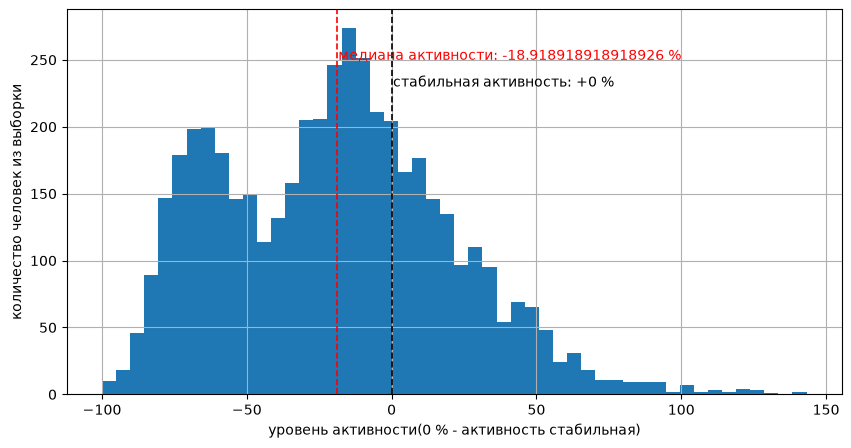

In [55]:
print('Квантили распределения активности')
print(df_clients_activity['activity_change'].quantile(np.linspace(0, 1, 11)).round(2).to_string())
print()
print('Параметры активности:')
print(df_clients_activity['activity_change'].describe().to_string())
print()
print(f'Клиентов с упадком активности: {(df_clients_activity['activity_change'] < 0).sum()}')
print(f'Клиентов с возросшей активностиью {(df_clients_activity['activity_change'] > 0).sum()}')
print()
print(f"Снизило активность более чем вдвое: {(df_clients_activity['activity_change'] < -50).sum()}")
print(f"Снизило активность но менее вдвое: {((df_clients_activity['activity_change'] > -50) & (df_clients_activity['activity_change'] < 0)).sum()}")

activity_median = df_clients_activity['activity_change'].median()
ax = df_clients_activity['activity_change'].hist(bins = 50, figsize = (10, 5))
plt.xlabel('уровень активности(0 % - активность стабильная)')
plt.ylabel('количество человек из выборки')
plt.axvline(activity_median, color="red", ls="--", lw=1.2)
plt.annotate(xy = (activity_median+0.5, 250), text = f"медиана активности: {activity_median} %", color = 'red')
plt.axvline(0, color="black", ls="--", lw=1.2)
plt.annotate(xy = (0+0.5, 230), text = f"стабильная активность: +0 %", color = 'black')

**Что видно:** 

1. 69.4 % клиентов снизили активность, коэфициент активности 0% появляется только на 70 квантиле.
2. Из-за этого выборка сильно скошена влево, медиана активности 0.81.
3. Выборка кажется бимодальной: виден первый горб около медианы, а второй около -70%.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Будем смотреть разрезы данных и выделять медианно падение активности в группе и количество человек в такой группе. Далее на основе увиденного будем группировать большие группы сконцентрированные в определенных участках и определять не пересакаются ли они. В случае пересечения будем определять насколько уровень активности клиента подходит под медианный в группе и добавлять его в более подходящую.

В качестве клиентов для отбора возьмем тех у кого есть соглашение на маркетинговое взаимодействие и у которых активность упала, т.к. повышение активности со стабльной это уже другая задача

In [56]:
# --- базовый код для исследования
groups = {}
df_clients_activity_grouped = df_clients_activity[
    (df_clients_activity['marketing_opt_in'] == 'Да') & (df_clients_activity['activity_change'] < 0)
]
df_clients_activity_grouped['activity_change'] = df_clients_activity_grouped['activity_change'].astype("float64")

print(f'Клиентов для группировки: {df_clients_activity_grouped.shape[0]}')

COLUMNS_RU = {
    "client_id":           "ID клиента",
    "birth_date":          "Дата рождения",
    "gender":              "Пол",
    "city":                "Город",
    "segment":             "Сегмент",
    "loyalty_tier":        "Уровень лояльности",
    "card_type":           "Тип карты",
    "registration_date":   "Дата прихода в банк",
    "card_open_date":      "Дата открытия карты",
    "income_source":       "Источник дохода",
    "monthly_income":      "Доход, ₽/мес",
    "has_mobile_app":      "Приложение установлено",
    "app_last_login":      "Последний вход в приложение",
    "satisfaction_score":  "Оценка обслуживания, 1–5",
    "marketing_opt_in":    "Согласие на коммуникацию",
    "2024_activity":       "Активность 2024, опер./мес",
    "2025_activity":       "Активность H1 2025, опер./мес",
    "activity_change":      "уроаень активности",
}
def build_heatmap_by_columns_and_activity_lavel(data, column1, column2, ax = None):
    if ax is None:
        ax = plt.gca()
    counts = data.pivot_table(
    index=column1, columns=column2,
    values="activity_change", aggfunc="size",
    observed=True, fill_value=0,
    ).T
    means = data.pivot_table(
        index=column1, columns=column2,
        values="activity_change", aggfunc="median",
        observed=True, fill_value=np.nan,
    ).T

    
    annot =  (means.round(2).astype(str) + '% ' + '(' + counts.astype(int).astype(str) + ')')
    sns.heatmap(means, annot=annot, cmap="Blues_r", fmt="", ax = ax)
    ax.set_xlabel(COLUMNS_RU[column1])
    ax.set_ylabel(COLUMNS_RU[column2])
    ax.set_title(f'Среднее изменение активности и количество клиентов по категориям\n"{COLUMNS_RU[column1]}" и "{COLUMNS_RU[column2]}"')
    ax.tick_params(axis="y", labelrotation=0)
    ax.tick_params(axis="x", labelrotation=0)
    return ax

Клиентов для группировки: 2852


Начнем анализ с срезов по сегменту, на анализе срезов данных он сильно был связан с другими параметрами.

Изменение по всем клиентам


,"медианное изменение активности, %",количество
segment,,
Private,-12.28,189
Зарплатный,-7.69,1304
Массовый,-34.65,2396
Премиальный,-14.19,784


Изменение клиентам с пониженной активностью и с согласием на обработку


,"медианное изменение активности, %",количество
segment,,
Private,-23.26,105
Зарплатный,-22.68,665
Массовый,-50.65,1659
Премиальный,-27.90,423


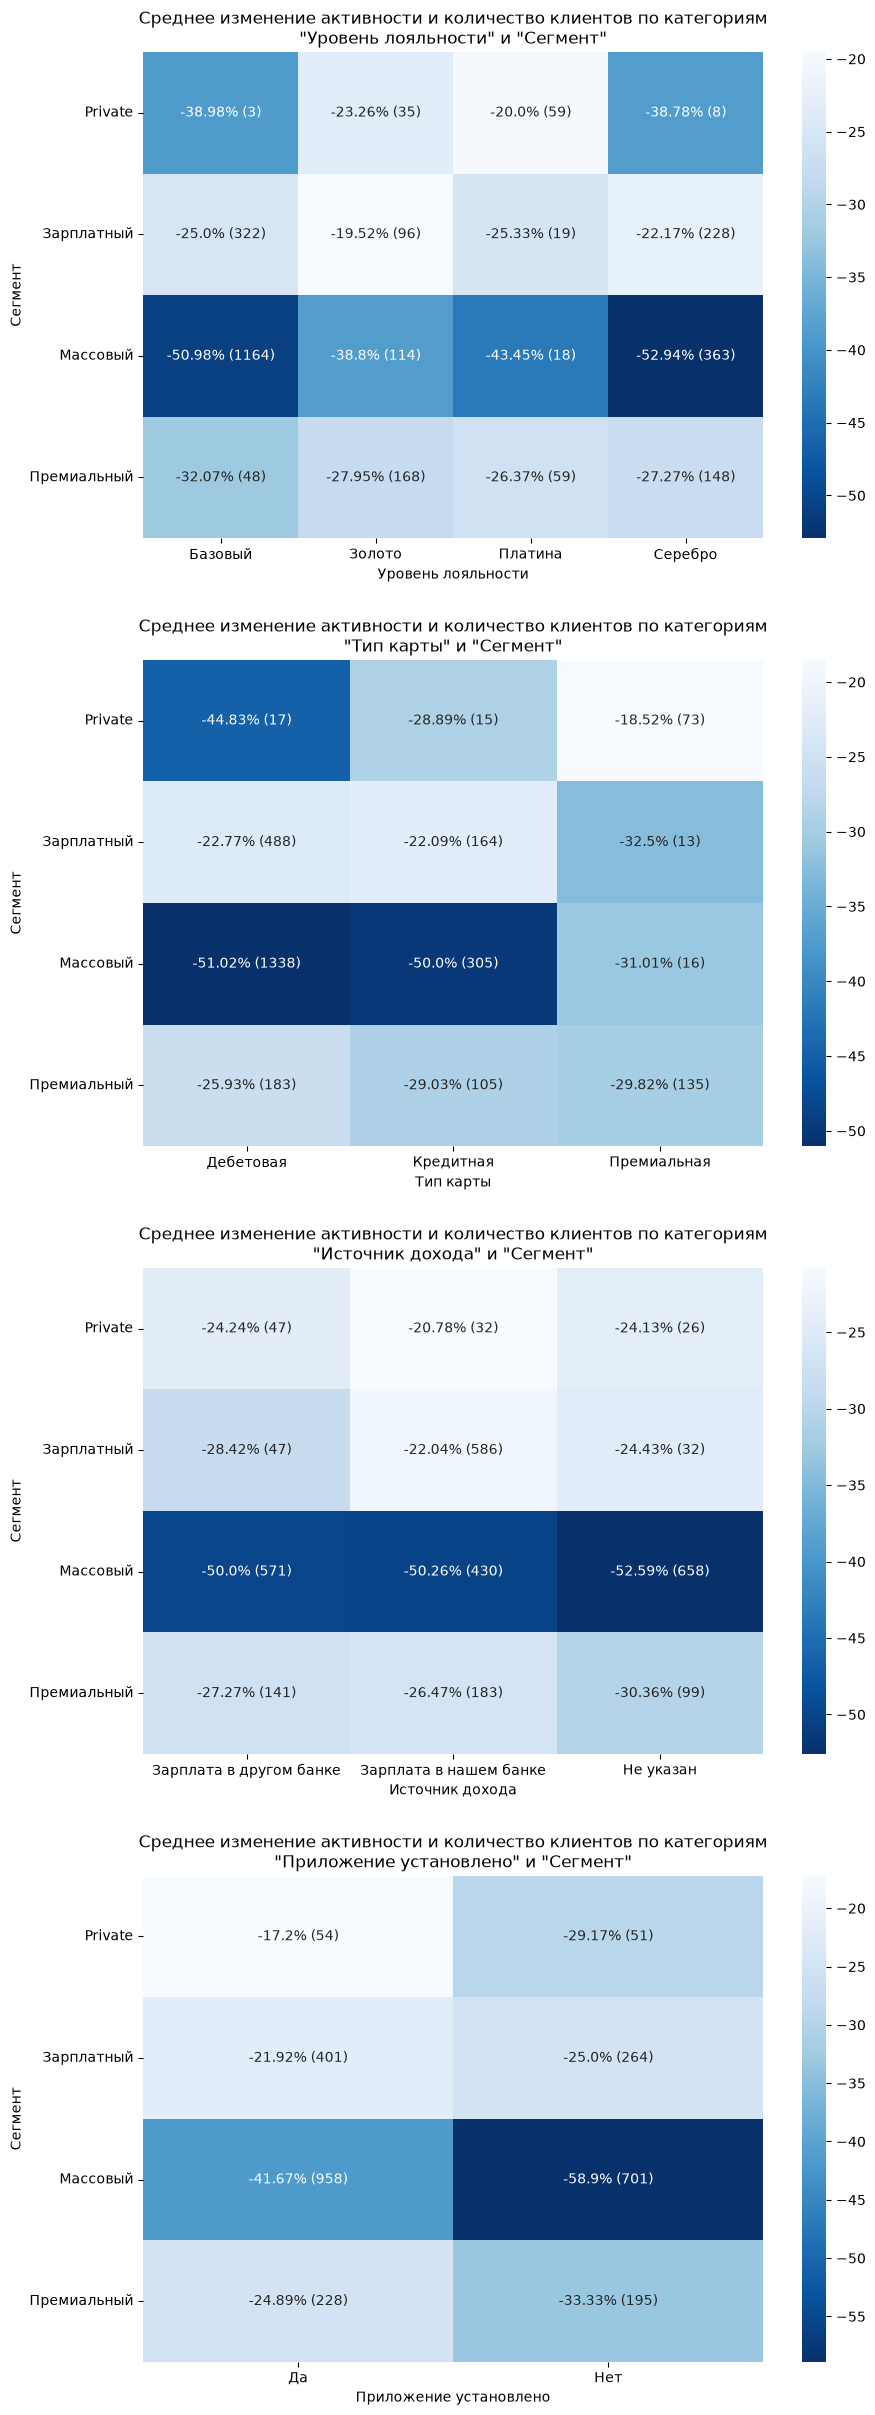

In [57]:
fig, axes = plt.subplots(4,1, figsize = (10, 30))
fig.subplots_adjust(hspace=0.25)
segment_to_feature = ['loyalty_tier', 'card_type', 'income_source','has_mobile_app']

segment_activity_agg = df_clients_activity_grouped.groupby('segment')['activity_change'].agg(
    **{'медианное изменение активности, %':'median', 'количество': 'count'})

segment_activity_full_agg = df_clients_activity.groupby('segment')['activity_change'].agg(
    **{'медианное изменение активности, %':'median', 'количество': 'count'})

for ax, feat in zip(axes.flat, segment_to_feature):
    build_heatmap_by_columns_and_activity_lavel(df_clients_activity_grouped, feat,"segment",ax)
print('Изменение по всем клиентам')
display(segment_activity_full_agg.round(2))
print('Изменение клиентам с пониженной активностью и с согласием на обработку')
display(segment_activity_agg.round(2))

**Вывод по срезам**

После фильтра «есть согласие на коммуникацию и активность упала» в выборке остаётся 2852 клиента, и по сегментам картина такая: Массовый — −50.6 % (1659 клиентов), Премиальный — −27.9 % (423), Private — −23.3 % (105), Зарплатный — −22.7 % (665).

Главное следствие фильтра: как только из выборки уходят клиенты, не потерявшие активность, три «благополучных» сегмента сжимаются в узкий коридор 22.7–27.9 %, а массовый так и остаётся ровно вдвое глубже — −50.6 %. То есть весь разброс по сегментам теперь создаёт один массовый сегмент, причём это не эффект малой выборки: он же и самый многочисленный — 1659 из 2852 клиентов.

Поэтому группу берём внутри массового сегмента, а делим её по наличию мобильного приложения. Причин три: этот признак относится к самому клиенту, а не к его операциям; он почти не различает сегменты (это уже видно из раздела 5.4), то есть не дублирует сегмент, а режет его изнутри; и он поддаётся действию — установке приложения, — в отличие от лояльности, типа карты и источника дохода, которые описывают состав той же группы, но не дают кампании отдельного рычага.

Деление по приложению подтверждается и характером падения (разбор в разделе 7.1): после обрезки порогом −20 % у группы без приложения медиана падения −63.6 % против −55.1 % с приложением, медиана дней с последней операции 24 против 10, а больше месяца не платили 41.2 % против 26.5 %. То есть приложение отделяет не только «кого звать», но и насколько глубоко человек уже вышел из ежедневного пользования картой.

Остальные срезы внутри сегмента (лояльность, тип карты, источник дохода) на этом шаге не берём: они не отделяют массовый сегмент от остальных, а лишь переописывают его состав.


In [58]:
groups['Массовый сегмент без приложения'] = df_clients_activity_grouped[
   (df_clients_activity_grouped['has_mobile_app'] == 'Нет') &
    (df_clients_activity_grouped['segment'] == 'Массовый')
]
groups['Массовый сегмент c приложением'] = df_clients_activity_grouped[
   (df_clients_activity_grouped['has_mobile_app'] == 'Да') &
    (df_clients_activity_grouped['segment'] == 'Массовый')
]

Проверим срез сегмента с городом, возможно так будет перкос(как мы ваяснили ранее в Казани перекос в сторону базового и массового секторов)

<Axes: title={'center': 'Среднее изменение активности и количество клиентов по категориям\n"Сегмент" и "Город"'}, xlabel='Сегмент', ylabel='Город'>

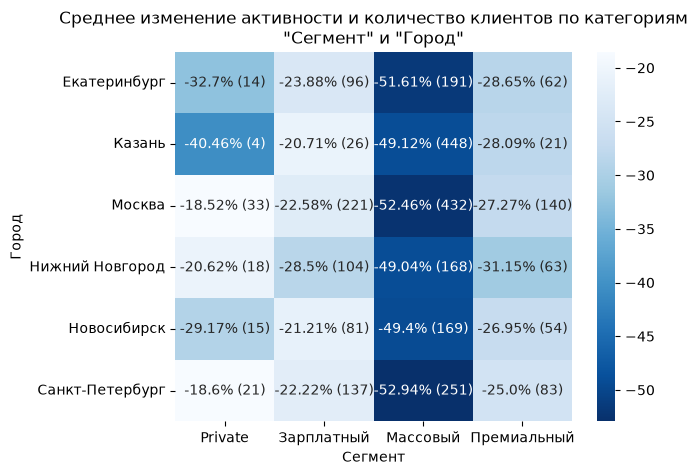

In [59]:
build_heatmap_by_columns_and_activity_lavel(df_clients_activity_grouped,'segment',"city")

Как видим уровень активности падает достаточно равномерна по городам в массовом сегмете −49…−53 %, следовательно города при фильтрации не учитываем

Если не фильтровать по городу, то имеет смысл дальше сфокусироваться на сегментах: выведем их активность за периоды:

In [60]:
# --- характеристики активности по сегментам
# потеря считается как активность2024 - активность H1 2025, в расчёт идут только
# положительные изменения темпа: рост у части клиентов потерю не компенсирует.
segment_activity = df_clients_activity_grouped.assign(
    потеря=lambda d: (d["2024_activity"] - d["2025_activity"].fillna(0)).clip(lower=0)
)
LOSS_TOTAL = segment_activity["потеря"].sum()


def segment_activity_stats(part: pd.DataFrame) -> pd.Series:
    change = part["activity_change"].dropna()
    return pd.Series(
        {
            "клиентов": len(part),
            "активность 2024, опер./мес": part["2024_activity"].median(),
            "активность H1 2025, опер./мес": part["2025_activity"].median(),
            "изменение, % (медиана)": change.median(),
            "падение более 50 %, %": change.lt(-50).mean() * 100,
            "потеря, опер./мес": part["потеря"].sum(),
            "доля потери, %": part["потеря"].sum() / LOSS_TOTAL * 100,
        }
    )


segment_activity_table = pd.concat(
    [segment_activity_stats(part).rename(name) for name, part in segment_activity.groupby("segment", observed=True)]
    + [segment_activity_stats(segment_activity).rename("Итого по когорте")],
    axis=1,
).T.round(1)
segment_activity_table["клиентов"] = segment_activity_table["клиентов"].astype(int)

print(
    f"когорта метрики активности: {len(segment_activity)} клиентов, "
    f"суммарная потеря {LOSS_TOTAL:.0f} опер./мес\n"
    f"медиана по когорте: {segment_activity['activity_change'].median():.1f} %\n"
)

body = segment_activity_table.drop("Итого по когорте").sort_values("изменение, % (медиана)")
pd.concat([body, segment_activity_table.loc[["Итого по когорте"]]])


когорта метрики активности: 2852 клиентов, суммарная потеря 6226 опер./мес
медиана по когорте: -37.0 %



,клиентов,"активность 2024, опер./мес","активность H1 2025, опер./мес","изменение, % (медиана)","падение более 50 %, %","потеря, опер./мес","доля потери, %"
Массовый,1659,4.4,2.2,-50.6,50.2,3760.2,60.4
Премиальный,423,6.3,4.2,-27.9,18.9,948.2,15.2
Private,105,6.3,4.7,-23.3,21.0,190.7,3.1
Зарплатный,665,6.0,4.0,-22.7,23.3,1326.6,21.3
Итого по когорте,2852,5.0,2.8,-37.0,38.2,6225.7,100.0


**Возьмем еще две группы:** зарплатый и премиальный сегмент

Массовый сегмент даёт 60.4 % всей потери активности — 3 760 операций в месяц из 6 226, — и делится на две группы по наличию приложения. Остальные сегменты устроены иначе: зарплатный при 665 клиентах даёт 21.3 % потери (1 326 операций), премиальный при 423 клиентах — 15.2 % (948 операций). Вместе это ещё 36.5 %, то есть больше трети потери, и оставлять их вне кампании нельзя.

По медиане падения они мягче: −22.7 % у зарплатного и −27.9 % у премиального против −50.6 % у массового. Но база у них выше — 6.0 и 6.3 операции в месяц против 4.4, поэтому процентная глубина меньше, а в абсолюте теряют они не мало: 1 326 и 948 операций в месяц, в сумме 2 274.

**Характер падения у этих двух сегментов разный, и это определяет, что им предлагать.** У зарплатного проседает повседневная корзина — «Продукты» дают 23.3 % потери сверх фона (−0.44 опер./клиента в месяц), «Транспорт» 15.2 %, «Кафе» 12.1 %; у премиального повседневные траты почти не затронуты, а теряются поездки и рестораны — «Транспорт» 26.4 % (−0.48), «Кафе и рестораны» 15.3 %, при этом «Аптеки» всего 1.6 %. Разбор причин по всем четырём группам — в разделе 7.1.

**Конфликтов не возникнет**

Группы заданы сегментом, а сегменты не пересекаются: один клиент не может быть одновременно зарплатным и премиальным. Приложение делит только массовый сегмент, и там оно тоже однозначно — либо установлено, либо нет. Поэтому отдельное правило разрешения конфликтов не нужно: каждый клиент попадает ровно в одну группу по построению правила.

**Кого не берём**

**Private** — 105 клиентов и 3.1 % потери, это 191 операция в месяц. Группа меньше 150 человек по условию задачи не рассматривается, а на фоне остальных сегментов вклад небольшой.

**Клиенты без заметного падения** — их изменение не выходит за пределы случайного разброса, поэтому в кампанию по возврату активности они не попадают.


In [61]:
groups['Зарплатный сегмент'] = df_clients_activity_grouped[
    (df_clients_activity_grouped['segment'] == 'Зарплатный')
]
groups['Премиальный сегмент'] = df_clients_activity_grouped[
    (df_clients_activity_grouped['segment'] == 'Премиальный')
]
for key, value in groups.items():
    print(f'группа: {key} содержит {len(value)} клинтов, медиана падения активности {value['activity_change'].median().round(2)}')

print(f'Всего людей в группах: {sum([len(value) for value in groups.values()])}')

группа: Массовый сегмент без приложения содержит 701 клинтов, медиана падения активности -58.9
группа: Массовый сегмент c приложением содержит 958 клинтов, медиана падения активности -41.67
группа: Зарплатный сегмент содержит 665 клинтов, медиана падения активности -22.68
группа: Премиальный сегмент содержит 423 клинтов, медиана падения активности -27.9
Всего людей в группах: 2747


Людей в группах слишком много, стоит срезать людей у которых активность упала выше некоторого порога: проверим распределение порогов и решим на каком уровне отсекать:

In [62]:
df_clients_activity_grouped['activity_change'].describe()

count    2852.000000
mean      -40.210881
std        25.343728
min      -100.000000
25%       -62.790698
50%       -36.986301
75%       -17.241379
max        -0.564972
Name: activity_change, dtype: float64

Но появляется проблема

In [63]:
# --- разброс, который даёт случайность: стандартное отклонение активности
# число успешных операций клиента за H1 2025 считаем пуассоновским: ожидание 6 × активность2024,
# стандартное отклонение — корень из ожидания. База берётся как медиана активности 2024.
noise = (
    df_clients_activity.groupby("segment", observed=True)["2024_activity"]
    .median()
    .to_frame("активность 2024, опер./мес")
)
noise["ожидание за H1 2025, операций"] = noise["активность 2024, опер./мес"] * 6
noise["ст. откл., операций"] = np.sqrt(noise["ожидание за H1 2025, операций"])
noise["ст. откл., опер./мес"] = noise["ст. откл., операций"] / 6
noise["относительное ст. откл., %"] = noise["ст. откл., опер./мес"] / noise["активность 2024, опер./мес"] * 100
noise["падение 10 %, σ"] = 10 / noise["относительное ст. откл., %"]
noise["падение 20 %, σ"] = 20 / noise["относительное ст. откл., %"]

print(
    "чем ниже база, тем сильнее случайные колебания относительно неё:\n"
    "при базе 4 опер./мес ожидается 24 операции за полгода, разброс ±5 операций, то есть ±20 %"
)

noise.round(1)


чем ниже база, тем сильнее случайные колебания относительно неё:
при базе 4 опер./мес ожидается 24 операции за полгода, разброс ±5 операций, то есть ±20 %


,"активность 2024, опер./мес","ожидание за H1 2025, операций","ст. откл., операций","ст. откл., опер./мес","относительное ст. откл., %","падение 10 %, σ","падение 20 %, σ"
segment,,,,,,,
Private,6.4,38.5,6.2,1.0,16.1,0.6,1.2
Зарплатный,5.8,35.0,5.9,1.0,16.9,0.6,1.2
Массовый,4.4,26.5,5.1,0.9,19.4,0.5,1.0
Премиальный,6.2,37.5,6.1,1.0,16.3,0.6,1.2


**Уровень отсечения активности**

Разброс, который даёт случайность, известен: при медианной базе 4.4–6.4 операции в месяц относительное стандартное отклонение активности за полгода составляет 16.1–19.4 %. Отсюда уровень отсечения — одно стандартное отклонение, то есть падение на 20 %: по сегментам это 1.0–1.2 σ.

Всё, что ниже, не отличимо от случайных колебаний. У клиента с 26 операциями за полгода разброс ±5 операций, и «падение» на 10 % (0.5–0.6 σ) целиком укладывается в этот интервал: возвращать там нечего, изменение в пределах шума.

Порог задан в процентах и одинаков для всех групп, поэтому для сегментов с высокой базой он чуть строже: при базе 6.4 достаточно 16 %, при базе 4.4 нужно 19 %. Единый процент — это компромисс между этими границами, а не подгонка под результат.


In [64]:
# --- Обрежем данные и выведем результат

In [65]:
for key, group in groups.items():
    group = group[group['activity_change'] <= -20]
    groups[key] = group
    print(f'группа: {key} содержит {len(group)} клинтов, медиана падения активности {group['activity_change'].median().round(2)}')

print(f'Всего людей в группах: {sum([len(value) for value in groups.values()])}')

группа: Массовый сегмент без приложения содержит 599 клинтов, медиана падения активности -63.55
группа: Массовый сегмент c приложением содержит 710 клинтов, медиана падения активности -55.07
группа: Зарплатный сегмент содержит 369 клинтов, медиана падения активности -42.31
группа: Премиальный сегмент содержит 284 клинтов, медиана падения активности -37.06
Всего людей в группах: 1962


In [66]:
# --- краткая сводка по группам, полученным после обрезки порогом -20 %
def group_summary(part: pd.DataFrame) -> pd.Series:
    change = part["activity_change"].dropna()
    loss = (part["2024_activity"] - part["2025_activity"].fillna(0)).clip(lower=0)
    return pd.Series(
        {
            "клиентов": len(part),
            "активность 2024, опер./мес": part["2024_activity"].median(),
            "активность H1 2025, опер./мес": part["2025_activity"].median(),
            "изменение активности, %": change.median(),
            "падение более 50 %, %": change.lt(-50).mean() * 100,
            "потеря, опер./мес": loss.sum(),
        }
    )


summary = pd.DataFrame({name: group_summary(part) for name, part in groups.items()}).T
summary["клиентов"] = summary["клиентов"].astype(int)
summary["доля клиентов, %"] = (summary["клиентов"] / summary["клиентов"].sum() * 100).round(1)
summary["доля потери, %"] = (
    summary["потеря, опер./мес"] / summary["потеря, опер./мес"].sum() * 100
).round(1)

print(
    f"групп: {len(groups)} | клиентов в группах: {summary['клиентов'].sum()} | "
    f"суммарная потеря: {summary['потеря, опер./мес'].sum():.0f} опер./мес\n"
)
display(summary.round(1))


групп: 4 | клиентов в группах: 1962 | суммарная потеря: 5467 опер./мес



,клиентов,"активность 2024, опер./мес","активность H1 2025, опер./мес","изменение активности, %","падение более 50 %, %","потеря, опер./мес","доля клиентов, %","доля потери, %"
Массовый сегмент без приложения,599,4.2,1.5,-63.6,72.5,1722.1,30.5,31.5
Массовый сегмент c приложением,710,4.3,1.8,-55.1,56.2,1836.2,36.2,33.6
Зарплатный сегмент,369,5.8,2.8,-42.3,42.0,1091.2,18.8,20.0
Премиальный сегмент,284,5.9,3.3,-37.1,28.2,817.7,14.5,15.0


Проверим возможные причины падения активности: посмотрим охват по категориям оплаты и проверим отстутствие ативности на продолжительном периоде

In [67]:
MONTHS = {2024: 12, 2025: 6}
BASE_END = pd.Timestamp("2024-12-31")
PERIOD_END = pd.Timestamp("2025-06-30")

def cat_delta(clients, ops):
    """вклад категорий в изменение операций на клиента в месяц, год к году."""
    n = clients["client_id"].nunique()
    part = ops[ops["client_id"].isin(clients["client_id"])]
    by = (part.groupby([part["txn_datetime"].dt.year, "category"], observed=True)
              .size().unstack(fill_value=0)
              .reindex(index=[2024, 2025], columns=part["category"].cat.categories, fill_value=0))
    base = by.loc[2024] / n / 12
    cur  = by.loc[2025] / n / 6
    out = pd.DataFrame({"2024": base, "H1_2025": cur})
    out["delta"] = out["H1_2025"] - out["2024"]
    return out

# фон
cohort = df_clients_activity
cohort_delta = cat_delta(cohort, df_ops_activity)

rows = []
for name, part in groups.items():
    d = cat_delta(part, df_ops_activity)
    d["delta_diff"] = d["delta"] - cohort_delta["delta"]   # вклад сверх фона
    total = d["delta_sum"] = d["delta_diff"].sum()
    d["share_of_loss, %"] = d["delta_diff"] / total * 100
    rows.append(d[["delta", "delta_diff", "share_of_loss, %"]].assign(group=name))

cat_table = pd.concat(rows).reset_index().rename(columns={"category": "категория", "group": "группа"})
cat_table.round(2).sort_values(["группа", "share_of_loss, %"])

,index,delta,delta_diff,"share_of_loss, %",группа
19,Аптеки,-0.20,-0.12,6.34,Зарплатный сегмент
24,Развлечения и досуг,-0.20,-0.13,6.99,Зарплатный сегмент
25,Связь и интернет,-0.23,-0.15,8.04,Зарплатный сегмент
22,Онлайн-сервисы,-0.22,-0.15,8.13,Зарплатный сегмент
21,Одежда и обувь,-0.26,-0.19,9.77,Зарплатный сегмент
18,АЗС,-0.28,-0.19,10.25,Зарплатный сегмент
20,Кафе и рестораны,-0.33,-0.23,12.06,Зарплатный сегмент
26,Транспорт,-0.52,-0.29,15.16,Зарплатный сегмент
23,Продукты,-0.71,-0.44,23.26,Зарплатный сегмент
15,Развлечения и досуг,-0.15,-0.08,5.43,Массовый сегмент c приложением


In [68]:
last_op = df_ops_activity.groupby("client_id")["txn_datetime"].max()

def recency(clients):
    ids = clients["client_id"]
    days = (PERIOD_END - last_op.reindex(ids)).dt.days
    return pd.Series({
        "клиентов": len(ids),
        "нет операций 30 дн., %": (days > 30).mean() * 100,
        "нет операций 60 дн., %": (days > 60).mean() * 100,
        "нет операций 90 дн., %": (days > 90).mean() * 100,
        "последняя операция до 2025-01-01, %": (last_op.reindex(ids) <= BASE_END).mean() * 100,
        "медиана дней с последней операции": days.median(),
    })

rec_table = pd.DataFrame({**{n: recency(p) for n, p in groups.items()},
                          "когорта (фон)": recency(cohort)}).T
rec_table.round(1)

,клиентов,"нет операций 30 дн., %","нет операций 60 дн., %","нет операций 90 дн., %","последняя операция до 2025-01-01, %",медиана дней с последней операции
Массовый сегмент без приложения,599.0,41.2,18.7,5.8,0.7,24.0
Массовый сегмент c приложением,710.0,26.5,11.5,4.9,0.6,10.0
Зарплатный сегмент,369.0,18.7,8.7,2.2,0.3,8.0
Премиальный сегмент,284.0,12.3,5.3,1.4,0.0,6.0
когорта (фон),4673.0,14.0,6.0,2.0,0.2,5.0


### 7.1. За счёт чего упала активность в группах

Две проверки: разложение падения по девяти категориям траты (операций на клиента в месяц, год к году, **сверх фона когорты** — 4 673 клиента, чтобы общий тренд банка не записывался в причину группы) и recency — сколько дней прошло с последней операции на 30.06.2025. Окно 2024-01-01 … 2025-06-30, канал СБП исключён, группы после порога −20 %: 1 962 клиента, потеря 5 467 операций в месяц.

**Что видно.**

1. **Это не переток трат между категориями.** У всех четырёх групп падение есть во всех девяти категориях и ни в одной нет роста — значит структура трат не перестроилась, сократилась сама частота пользования картой. Версия «клиенты стали платить в другом месте» данными не подтверждается.
2. **Массовый сегмент теряет повседневную корзину.** «Продукты» дают треть потери сверх фона: −0.60 опер./клиента в месяц (33.1 % вклада) у группы без приложения и −0.49 (32.2 %) у группы с приложением; остальное — «Кафе», «Одежда», «Аптеки», «Связь», «Транспорт», «АЗС» по 8–10 % каждая. Карта перестаёт использоваться для того, что покупают каждую неделю, а не для разовых покупок.
3. **Премиальный сегмент режет другое.** Максимум потери — «Транспорт» 26.4 % (−0.48 опер./клиента в месяц) и «Кафе и рестораны» 15.3 % (−0.28); «Продукты» только 12.1 % (−0.22), «Аптеки» — 1.6 % (−0.03). Это сокращение дискреционных трат (поездки, рестораны), а не отказ от повседневных покупок.
4. **Зарплатный — между ними:** «Продукты» 23.3 % (−0.44), «Транспорт» 15.2 % (−0.29), «Кафе» 12.1 % (−0.23).
5. **Recency подтверждает механизм.** У массового без приложения 41.2 % клиентов не совершали операций больше 30 дней (фон 14.0 %), 18.7 % — больше 60 (фон 6.0 %), медиана 24 дня против 5 в фоне, то есть в 4.8 раза. Это уже не «платит реже», а «почти перестал пользоваться картой». При этом дольше 90 дней — только 5.8 %: полностью неактивных мало, карта остаётся «в кошельке», возвращать есть к чему. У остальных групп медиана 10, 8 и 6 дней.

**Чего эти проверки не показали:** доля клиентов с последней операцией до 01.01.2025 — 0.0–0.7 % у всех групп, поэтому падение не объясняется уходом из банка ещё до оцениваемого периода.

#### Описания групп: кто это, что произошло и за счёт чего

**1. Массовый сегмент без приложения** — 599 клиентов, 30.5 % групп и 31.5 % потери (1 722 опер./мес).
*Что произошло:* активность 4.2 → 1.5 опер./клиента в месяц, медиана −63.6 %, у 72.5 % падение больше чем вдвое — самая глубокая и продолжающаяся деградация.
*За счёт чего:* уход из повседневных трат. «Продукты» −0.87 опер./клиента в месяц (треть потери сверх фона), дальше «Кафе» −0.28, «Аптеки» и «Одежда» −0.25, «Связь» −0.24. Recency 24 дня против 5 в фоне: карта выпала из ежедневного оборота, но не закрыта.

**2. Массовый сегмент с приложением** — 710 клиентов, 36.2 % и 33.6 % потери (1 836 опер./мес).
*Что произошло:* 4.3 → 1.8 опер./клиента в месяц, медиана −55.1 %, у 56.2 % падение больше чем вдвое.
*За счёт чего:* та же повседневная корзина, но мягче: «Продукты» −0.76 (−0.49 сверх фона), «Транспорт» и «Связь» −0.40 и −0.24. Recency 10 дней, больше месяца не платили 26.5 % — вдвое реже, чем в группе без приложения.

**3. Зарплатный сегмент** — 369 клиентов, 18.8 % и 20.0 % потери (1 091 опер./мес).
*Что произошло:* база выше — 5.8 → 2.8 опер./клиента в месяц, медиана −42.3 %, у 42.0 % падение больше чем вдвое.
*За счёт чего:* «Продукты» −0.71 (23.3 % вклада), «Транспорт» −0.52 (15.2 %), «Кафе» −0.33. Recency 8 дней, 18.7 % не платили больше месяца — потеря ровнее распределена по категориям, чем у массового.

**4. Премиальный сегмент** — 284 клиента, 14.5 % и 15.0 % потери (818 опер./мес).
*Что произошло:* 5.9 → 3.3 опер./клиента в месяц, медиана −37.1 %, у 28.2 % падение больше чем вдвое. По месячному ряду падение здесь **остановилось** и не углубляется.
*За счёт чего:* «Транспорт» −0.72 (26.4 %) и «Кафе и рестораны» −0.38 (15.3 %) — сокращение поездок и ресторанов; повседневная корзина затронута слабо («Продукты» −0.49, «Аптеки» −0.11). Recency 6 дней — пользование картой сохранилось.


In [69]:
# --- 7.2.1. Короткие описания групп: ключ groups = «кто это + что произошло»
GROUP_TITLES = {
    "Массовый сегмент без приложения": "Массовый без приложения — ушли из повседневных трат",
    "Массовый сегмент c приложением": "Массовый с приложением — реже повседневные покупки",
    "Зарплатный сегмент": "Зарплатный — ровное падение по всем категориям",
    "Премиальный сегмент": "Премиальный — реже транспорт и рестораны",
}

groups = {GROUP_TITLES.get(name, name): part for name, part in groups.items()}

for name, part in groups.items():
    print(
        f"{name}: {len(part)} чел., медиана {part['activity_change'].median():.1f} %, "
        f"{part['2024_activity'].median():.1f} → {part['2025_activity'].median():.1f} опер./мес"
    )

Массовый без приложения — ушли из повседневных трат: 599 чел., медиана -63.6 %, 4.2 → 1.5 опер./мес
Массовый с приложением — реже повседневные покупки: 710 чел., медиана -55.1 %, 4.3 → 1.8 опер./мес
Зарплатный — ровное падение по всем категориям: 369 чел., медиана -42.3 %, 5.8 → 2.8 опер./мес
Премиальный — реже транспорт и рестораны: 284 чел., медиана -37.1 %, 5.9 → 3.3 опер./мес


### 7.2. Кого в кампанию не берём и почему

**Кого не берём в кампанию**

В результате анализа были отброшены следующие кандидаты на группировку:

- **Клиенты без согласия на коммуникацию** — 549 человек (11.7 % когорты): обращаться к ним нельзя, и это ограничение режет около 12 % аудитории в любом сегменте.
- **Клиенты с выросшей или стабильной активностью** — 1 272 человека из когорты 4 673: у них падения нет, поэтому они относятся к другой задаче, а не к возврату активности.
- **Клиенты с падением в пределах случайного разброса** — 836 человек (29.3 % когорты, медиана изменения −11.1 %): при относительном стандартном отклонении 16–19 % такое падение неотличимо от шума.
- **Клиенты Private-сегмента** — 105 человек и 3.1 % потери (191 опер./мес): группа меньше порога в 150 человек, заданного условием.
- **Клиенты с картой, открытой в 2024–2025 годах** — 789 человек (14.0 % базы): базовый период 2024 у них наблюдается не целиком, поэтому сравнивать периоды не с чем.
- **Клиенты с базовой активностью меньше 1 операции в месяц** — 172 человека: одна операция за год сдвигает их базу на 33 %, и отношение двух периодов на них неустойчиво.
- **Клиенты без единой состоявшейся операции за 18 месяцев** — 15 человек из справочника: наблюдать у них нечего.

После обрезки вне групп остаётся 54 клиента — это Private-сегмент, который не проходит порог в 150 человек. Все остальные клиенты с падением ≤ −20 % попадают ровно в одну из четырёх групп: пересечений между группами нет, а 1 962 клиента укладываются в лимит 2 000.


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

✓ — гипотеза подтвердилась, ✗ — не подтвердилась.

- ✗ **`mcc_code` соответствует категории траты** (описание поля): 1 707 строк в аудите (0.27 %) и 1 606 после удаления дублей и операций клиентов вне справочника несут код чужой категории, поле удалено в пользу `category`.
- ✗ **`branch_code` описывает отделение клиента**: 840 значений на 5 649 клиентов и 3.9 города на отделение — поле удалено.
- ✓ **Дубли объясняют расхождение `txn_id` и количества строк**: после удаления 1 281 полного дубля и 219 записей с потерянным временем разность «ожидание − факт» равна нулю во всех 18 месяцах.
- ✗ **`00:00:00` — признак только дублей**: 219 пар да, но ещё 49 683 записи без пары, то есть время потеряно у ~8 % операций и часовой разрез невозможен.
- ✓ **Недостача февраля–марта 2025 целиком лежит в СБП**: факт по СБП на 44.2 % и 44.5 % ниже ожидания, остальные каналы в пределах ±2.1 %; после восстановления доля СБП 17.5–17.8 % как в остальных месяцах.
- ✓ **Сдвиг каналов — это переток «Карта → Токен», а не искажение**: Карта 53 → 45 %, Токен 14 → 22 %, СБП и Онлайн-банк стабильны (17.3–17.9 % и 14.7–15.7 %).
- ✗ **Исключение СБП меняет вывод о падении активности**: −20.3 % со СБП против −17.9 % без СБП, а на чистых месяцах −12.5 % против −12.3 %, то есть вывод устойчив.
- ✗ **Падение активности объясняется городом** (перекос Казани из 5.4): в массовом сегменте падение −49…−53 % во всех шести городах, города не фильтруем.
- ✗ **Канал оплаты связан с категорией траты**: во всех девяти категориях распределение одинаково (≈51 / 17 / 17 / 15 %), канал как признак «кто это» дублирует сам себя.
- ✗ **Наличие приложения различает сегменты**: 56.1 % у Private против 62.2 % у зарплатного, согласие на коммуникацию 87.2–88.4 % во всех сегментах — признак годится как рычаг кампании, а не как описание сегмента.
- ✗ **Валюта собрана у узкой группы клиентов**: хотя бы одна не-рублёвая операция есть у 1 790 клиентов из 5 634 (31.8 %), медиана доли валюты у клиента 0.97 %, а медианы приведённых сумм совпадают с рублёвыми (1 066 против 1 069 ₽) — исключать валюту было бы хуже, чем привести к рублю.
- ✗ **Верхний хвост дохода и сумм — ошибки ввода**: 394 дохода (7.7 %) и 46 414 операций (8.1 %) выше границы Тьюки, но это Private и Платина с 0.8–1.2 млн ₽ и покупка на 116 694 ₽; распределения лог-нормальные, поэтому оставлены, а меры центра — медиана и IQR.
- ✓ **`monthly_income` местами записан в тысячах**: 170 значений `0 < x < 1000` после ×1000 дают квантили 52 550 / 74 250 / 104 250 ₽ против 55 000 / 75 800 / 111 775 ₽ в основном кластере.
- ✗ **`app_last_login` потерян при выгрузке**: пусто ровно у 2 189 клиентов без приложения и ни у одного с приложением — пропуск структурный.
- ✓ **Пропуски `satisfaction_score` зависят от сегмента** (и смещают «среднюю оценку»): ответили 33.2 % Private против 65.6 % Массового.
- ✓ **Возраст 88+ — не битые строки, а срез сверху с уплотнением**: 121 клиент на 88 годах против 21.9 в среднем за 80–87 и ни одного старше 88.93; профиль группы правдоподобен (медиана 58 операций, 27 из 121 с приложением), поэтому группа не удалена, но числовой возраст на этом участке не используется.
- ✓ **Массовый сегмент — источник основной потери активности**: 60.4 % потери при медиане −50.6 % против −22.7…−27.9 % у зарплатного, премиального и Private.
- ✗ **Рост и падение активности можно описывать одной метрикой «среднее изменение»**: 69.4 % клиентов снизили активность, медиана −37.0 % при среднем −40.2 %, а рост у части клиентов потерю не компенсирует — поэтому потеря считается как сумма положительных разниц темпа.


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [70]:
cleaning_log = pd.DataFrame(
    log_rows,
    columns=["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"],
)

In [71]:
campaign = pd.DataFrame(columns = ["client_id", "group"])
for key, group in groups.items():
    group_clients = pd.DataFrame(group['client_id'])
    group_clients['group'] = key
    campaign = pd.concat([campaign, group_clients], axis = 0)
campaign.head(10)

,client_id,group
0,C002786,Массовый без приложения — ушли из повседневных...
64,C003744,Массовый без приложения — ушли из повседневных...
70,C002682,Массовый без приложения — ушли из повседневных...
96,C001180,Массовый без приложения — ушли из повседневных...
104,C003309,Массовый без приложения — ушли из повседневных...
122,C002302,Массовый без приложения — ушли из повседневных...
123,C005627,Массовый без приложения — ушли из повседневных...
125,C004776,Массовый без приложения — ушли из повседневных...
154,C004760,Массовый без приложения — ушли из повседневных...
155,C000656,Массовый без приложения — ушли из повседневных...


In [72]:
df_clients_activity.to_parquet("clean/clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")

In [73]:
# --- выгрузка для отчёта (02_report.ipynb): операции когорты и воронка отбора клиентов
df_ops_activity[["client_id", "txn_datetime", "category", "channel", "amount_rub"]].to_parquet(
    "clean/clean_ops.parquet", index=False
)

n_no_ops = len(df_clients) - df_ops["client_id"].nunique()
funnel_clients = pd.DataFrame(
    [
        ("клиентов в справочнике после очистки", len(df_clients)),
        ("нет ни одной состоявшейся операции за 18 мес.", n_no_ops),
        ("карта открыта в 2024–2025: базовый период неполный", int((~clients_card_before_24_mask).sum()) - n_no_ops),
        ("меньше 1 операции в месяц в базе 2024", int(clients_card_before_24_mask.sum()) - len(df_clients_activity)),
        ("когорта метрики активности", len(df_clients_activity)),
    ],
    columns=["шаг", "клиентов"],
)
funnel_clients.to_csv("clean/clean_funnel.csv", index=False, encoding="utf-8")

print(f"clean_ops.parquet: {len(df_ops_activity):,} операций".replace(",", " "))
print(funnel_clients.to_string(index=False))

clean_ops.parquet: 465 745 операций
                                               шаг  клиентов
              клиентов в справочнике после очистки      5649
     нет ни одной состоявшейся операции за 18 мес.        15
карта открыта в 2024–2025: базовый период неполный       789
             меньше 1 операции в месяц в базе 2024       172
                        когорта метрики активности      4673
